# QUANT Summary Statistics Experiment Analysis

**How the numbers are built**

1. Only runs with `status == "ok"` are used, and only resamples that succeeded for **every** configuration (so every comparison is paired on identical train/test splits).
2. For each dataset × configuration × classifier, accuracy, feature count and timings are **averaged over the resamples** (timings can switch to the median with `TIME_AGG`).
3. Every configuration is compared to the baseline *within the same dataset*, giving per-dataset accuracy differences, relative error reduction, and feature/time reductions (positive = better than baseline).
4. Datasets are split into size groups (equal-count percentile bins) and into dataset types (Image, Sensor, Motion, ...), and the group analyses are repeated for both, to see where a configuration helps or hurts.

> Use a separate results CSV per configuration. The `run.py` resume key is dataset + resample + classifier, so sharing one output file across configurations can cause runs to be skipped.

# Experiment description

## What experiments are based on
Features in quant are taken as quantile values taken from intervals of the original datasets. Intervals of different sizes are taken for each dataset by taking intervals at different depths. At depth $d$ for any dataset sample, the number of intervals $I_n$ taken from the dataset is calculated as:
$$
I_{n} = 2^{d-1}
$$

Where the length of each interval $m$ for a sample of length $n$ is:

$$
m = \frac{n}{2^{d-1}}
$$

In the original paper, shift intervals were also taken at each depth. These intervals had the same interval length as the original intervals at this depth, but one less it taken than in the normal intervals, and the interval start position are shifted by half an interval width, as shown below.

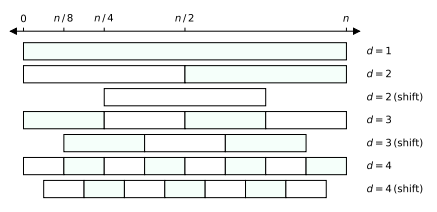

In the original paper, the number of quantiles, $k$, taken per interval of length $m$ is calculated as:

$$
k = \frac{m}{v}
$$

Where $v$ is a constant, which was set to 4 in QUANT, and 8 in QUANT $^{FAST}$. This meant that, particularly at lower levels of d, many quantile values were taken at each interval.

## Experiments Conducted
These experiments involved replacing interval quantile values with summary statistics. The idea of this experimentation was to try to replace intervals with large numbers of quantiles with fewer summary statistics, resulting in fewer features per interval. The summary statistics chosen were also cheaper to computer than quantiles, since none of the statistics used required intervals to be sorted as done in quant, which is a $O(n) = m \log{n}$ computational step. The statistics computed here only required one pass over the interval each ($O(n) = n$). These statistics included 

Order-free statistics (describe the distribution of values in the interval)
- mean, std, min, max : the usual
- nmp: normalised mean position, (mean - min) / (max - min); 0.5 when the mean is half way between the observed minimum and maximum
- skew: skewness (direction of asymmetry)
- kurt: excess kurtosis (tail weight; off by default, mostly redundant with skew/min/max)

Temporal statistics (depend on the order of the values in the interval)
- slope: least-squares slope of the values against time (per time step)
- argmax: position of the maximum within the interval, in [0, 1]
- argmin: position of the minimum within the interval, in [0, 1]
- mac: mean absolute change between consecutive values (roughness)
- mcr: mean-crossing rate (fraction of consecutive pairs that cross the mean)

These statistics were selected to capture both the distribution of values in the intervals and their temporal arrangement. Order free statistics describe the distribution independently of observation order, while temporal statistics describe characteristics of how values change throughout the interval.

The experiments conducted using these statistics included the following.

| Experiment Name | Description | Experiments Conducted | Results |
| --------------- | ----------- | --------------------- | ------- |
| basic_baseline | Baseline with only quantile features | Ran for all datasets (142) and resamples (30) | N/a |
| all_stats | This test replaced quantile features at all depths with summary statistics | Ran for all datasets (142) and resamples (30) | Initial results weren't promising enough to continue |
| double_stats | This test replaced quantile features with summary stats at depths which would have twice as many summary features as quantiles per interval or less | Ran for all datasets (142) and resamples (30) | Initial results weren't promising enough to continue |
| equal_stats | This test replaced quantile features with summary stats at depths which would have as many summary features as quantiles per interval or less | Ran for all datasets (142) and resamples (30) | Initial results weren't promising enough to continue |
| half_stats | This test replaced quantile features with summary stats at depths which would have half as many summary features as quantiles per interval or less | Ran for all datasets (142) and resamples (30) | Initial results weren't promising enough to continue |

This first set of experiments used all statistical measures for all intervals where statistical measures were used. The plan for these experiments was to continue with the most promising configurations to see which of the statistical measures were most important/if any could be removed. Unfortunately, none of these first experiments were promising enough to continue, since even with all statistical measures used the best results had too significant of an accuracy reduction compared to QUANT. 


## 1. Configuration

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display
from scipy import stats

# --- Inputs -----------------------------------------------------------------
RESULTS_DIR = Path("../results")

# CSV filename stem -> display label. Each stem must have <RESULTS_DIR>/<stem>.csv
CONFIG_LABELS = {
    "basic_baseline": "Baseline (Quant Features)",
    "all_stats": "Stats at every depth",
    "half_stats": "Stats at depths with twice as many quantiles",
    "equal_stats": "Stats at depths with same quantiles",
    "double_stats": "Stats at depths with half as many quantiles"
}
BASELINE = "Baseline (Quant Features)"   # must be one of the labels above

CLASSIFIERS = None                    # e.g. ["extratrees"]; None = all found in the CSVs

# --- Aggregation / statistics -----------------------------------------------
TIME_AGG = "mean"                     # how timings are combined over resamples: "mean" or "median"
TIE_TOL = 1e-12                       # |accuracy difference| below this counts as a tie
N_BOOTSTRAP = 5000                    # bootstrap resamples for the mean-difference confidence interval
ERROR_EPS = 0.001                     # pseudo-error added to BOTH errors in the smoothed error ratio (0.001 = 0.1 pp)
                                      # ideally ~0.5 / n_test; try 0.0005 and 0.002 to check the conclusions do not change
SEED = 0

# --- Dataset-size groups ----------------------------------------------------
N_SIZE_GROUPS = 5                     # equal-count percentile bins (5 = quintiles)
# Optional CSV with one row per dataset: dataset, n_train, series_length[, n_channels]
# (or a single precomputed `size` column). If None, the notebook looks for such
# columns in the results CSVs, and otherwise falls back to a runtime-based proxy.
SIZE_METADATA_CSV = None              # e.g. Path("../dataset_metadata.csv")

# --- Dataset types ----------------------------------------------------------
TYPES_CSV = Path("../improvedQuant/dataSetLists/dataset_types.csv")   # one row per dataset: dataset, type, type_group, ...
TYPE_COLUMN = "type_group"            # "type_group" (rare types merged into Other) or "type" (original archive types)
MIN_DATASETS_PER_GROUP = 8            # groups with fewer datasets get no CD diagram

print("Results directory:", RESULTS_DIR.resolve())

Results directory: C:\Users\davyt\quant-reproduction\results


## 2. Load and validate

Missing or malformed files are reported rather than silently skipped, and the notebook stops if the baseline is not available.

In [2]:
REQUIRED = {
    "dataset", "resample", "classifier", "accuracy", "status", "n_features",
    "time_transform_train", "time_fit", "time_transform_test", "time_predict",
}
NUMERIC = [
    "accuracy", "balanced_accuracy", "n_features",
    "time_transform_train", "time_fit", "time_transform_test", "time_predict",
]

frames, load_issues = [], []
for stem, label in CONFIG_LABELS.items():
    path = RESULTS_DIR / f"{stem}.csv"
    try:
        frame = pd.read_csv(path)
    except Exception as exc:
        load_issues.append({"file": str(path), "issue": f"Could not read: {exc}"})
        continue
    missing = sorted(REQUIRED - set(frame.columns))
    if missing:
        load_issues.append({"file": str(path), "issue": "Missing columns: " + ", ".join(missing)})
        continue
    frame["configuration"] = label
    for col in NUMERIC:
        frame[col] = pd.to_numeric(frame[col], errors="coerce") if col in frame else np.nan
    frame["resample"] = pd.to_numeric(frame["resample"], errors="coerce")
    frame["status"] = frame["status"].fillna("").astype(str)
    frames.append(frame)

if load_issues:
    display(pd.DataFrame(load_issues))
if not frames:
    raise FileNotFoundError("No usable result CSVs found. Check RESULTS_DIR and CONFIG_LABELS.")

results = pd.concat(frames, ignore_index=True, sort=False)
if BASELINE not in set(results["configuration"]):
    raise ValueError(f"Baseline '{BASELINE}' was not loaded. Loaded: {sorted(results['configuration'].unique())}")
if CLASSIFIERS is not None:
    results = results[results["classifier"].isin(CLASSIFIERS)].copy()

# Duplicated runs would double-count a resample, so keep the first and say so.
run_key = ["configuration", "dataset", "classifier", "resample"]
n_dup = int(results.duplicated(run_key).sum())
if n_dup:
    print(f"WARNING: dropped {n_dup} duplicated runs (same configuration/dataset/classifier/resample).")
    results = results.drop_duplicates(run_key, keep="first")

results["is_success"] = results["status"].str.lower().eq("ok") & results["accuracy"].notna()

print(f"Loaded {len(results):,} runs from {len(frames)} file(s); "
      f"{int(results['is_success'].sum()):,} successful.")
display(
    results.groupby(["configuration", "classifier", "status"]).size()
    .rename("runs").reset_index()
)

Loaded 21,300 runs from 5 file(s); 21,300 successful.


,configuration,classifier,status,runs
0,Baseline (Quant Features),extratrees,ok,4260
1,Stats at depths with half as many quantiles,extratrees,ok,4260
2,Stats at depths with same quantiles,extratrees,ok,4260
3,Stats at depths with twice as many quantiles,extratrees,ok,4260
4,Stats at every depth,extratrees,ok,4260


## 3. Paired runs and per-dataset averages

A resample is kept only if the same dataset/classifier/resample succeeded in **all** configurations, so every configuration is averaged over the same splits. The table `table` has one row per dataset × configuration × classifier and is used by everything below.

In [3]:
ok = results.loc[results["is_success"]].copy()
ok["time_train_total"] = ok["time_transform_train"] + ok["time_fit"]
ok["time_test_total"] = ok["time_transform_test"] + ok["time_predict"]

# Keep only resamples that succeeded in every configuration.
all_configs = sorted(ok["configuration"].unique())
pair_key = ["dataset", "classifier", "resample"]
n_cfg = ok.groupby(pair_key)["configuration"].transform("nunique")
paired = ok.loc[n_cfg == len(all_configs)].copy()
print(f"Configurations: {all_configs}")
print(f"Successful runs: {len(ok):,} -> kept {len(paired):,} runs in complete resample sets "
      f"({len(ok) - len(paired):,} dropped).")

TIME_COLS = ["time_transform_train", "time_fit", "time_transform_test", "time_predict",
             "time_train_total", "time_test_total"]
agg_spec = {
    "accuracy": ("accuracy", "mean"),
    "balanced_accuracy": ("balanced_accuracy", "mean"),
    "n_features": ("n_features", "mean"),
    "n_resamples": ("resample", "nunique"),
}
agg_spec.update({c: (c, TIME_AGG) for c in TIME_COLS})

table = (
    paired.groupby(["dataset", "classifier", "configuration"], as_index=False)
    .agg(**agg_spec)
)
table["error"] = 1 - table["accuracy"]

# Coverage check: every dataset should appear in every configuration with the same resample count.
cov = table.groupby(["classifier", "configuration"]).agg(
    datasets=("dataset", "nunique"),
    resamples_min=("n_resamples", "min"),
    resamples_median=("n_resamples", "median"),
    resamples_max=("n_resamples", "max"),
)
display(cov)
print(f"{table['dataset'].nunique()} datasets in the analysis table.")

Configurations: ['Baseline (Quant Features)', 'Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', 'Stats at depths with twice as many quantiles', 'Stats at every depth']
Successful runs: 21,300 -> kept 21,300 runs in complete resample sets (0 dropped).


datasets  \
classifier configuration                                            
extratrees Baseline (Quant Features)                          142   
           Stats at depths with half as many quantiles        142   
           Stats at depths with same quantiles                142   
           Stats at depths with twice as many quantiles       142   
           Stats at every depth                               142   

                                                         resamples_min  \
classifier configuration                                                 
extratrees Baseline (Quant Features)                                30   
           Stats at depths with half as many quantiles              30   
           Stats at depths with same quantiles                      30   
           Stats at depths with twice as many quantiles             30   
           Stats at every depth                                     30   

                                                         resamples_median  \
classifier configuration                                                    
extratrees Baseline (Quant Features)                                 30.0   
           Stats at depths with half as many quantiles               30.0   
           Stats at depths with same quantiles                       30.0   
           Stats at depths with twice as many quantiles              30.0   
           Stats at every depth                                      30.0   

                                                         resamples_max  
classifier configuration                                                
extratrees Baseline (Quant Features)                                30  
           Stats at depths with half as many quantiles              30  
           Stats at depths with same quantiles                      30  
           Stats at depths with twice as many quantiles             30  
           Stats at every depth                                     30

142 datasets in the analysis table.


## 4. Dataset-size groups

QUANT's cost scales with the number of training cases × series length × channels, so that is the preferred size measure. The notebook uses, in order:

1. `SIZE_METADATA_CSV` (or columns in the results CSVs) with `n_train` and `series_length` (and optionally `n_channels`);
2. a single `size` column, if present;
3. otherwise a **runtime proxy**: the geometric mean of `time_transform_train` across configurations. This is a reasonable stand-in for data volume, but it is measured, so noisy timings can nudge a dataset into a neighbouring group. Use real metadata for anything you plan to publish.

Groups are equal-count percentile bins (`N_SIZE_GROUPS`), so each group has roughly the same number of datasets.

In [4]:
SIZE_ALIASES = {
    "n_train": ["n_train", "n_train_cases", "n_cases_train", "train_size"],
    "length": ["series_length", "n_timepoints", "n_timesteps", "length"],
    "channels": ["n_channels", "n_dimensions", "n_dims"],
    "size": ["size", "dataset_size"],
}

def find_col(df, key):
    return next((c for c in SIZE_ALIASES[key] if c in df.columns), None)

def size_from_frame(df):
    # Return (Series indexed by dataset, description) or None if no usable columns.
    per_dataset = df.groupby("dataset").first()
    n_train, length, chans = (find_col(per_dataset, k) for k in ("n_train", "length", "channels"))
    if n_train and length:
        size = per_dataset[n_train] * per_dataset[length]
        if chans:
            size = size * per_dataset[chans].fillna(1)
        return size, "n_train × series_length" + (" × n_channels" if chans else "")
    size_col = find_col(per_dataset, "size")
    if size_col:
        return per_dataset[size_col], size_col
    return None

size_info = None
if SIZE_METADATA_CSV is not None:
    size_info = size_from_frame(pd.read_csv(SIZE_METADATA_CSV))
    if size_info is None:
        raise ValueError("SIZE_METADATA_CSV needs n_train + series_length columns, or a `size` column.")
if size_info is None:
    size_info = size_from_frame(results)

if size_info is not None:
    dataset_size, SIZE_DESC = size_info
    dataset_size = dataset_size.reindex(table["dataset"].unique())
    if dataset_size.isna().any():
        raise ValueError(f"No size for datasets: {list(dataset_size.index[dataset_size.isna()])[:10]}")
else:
    SIZE_DESC = "runtime proxy (geometric mean of training-transform time, s)"
    dataset_size = (
        table.groupby("dataset")["time_transform_train"]
        .apply(lambda s: float(np.exp(np.log(s.clip(lower=1e-9)).mean())))
    )
    print("NOTE: no dataset-size metadata found, using a runtime proxy for size groups.")

dataset_size = dataset_size.astype(float).sort_values()
# Rank first so ties can't collapse bins; groups end up equal-sized (±1 dataset).
bin_id = pd.qcut(dataset_size.rank(method="first"), N_SIZE_GROUPS, labels=False)

group_label = {}
for g in range(N_SIZE_GROUPS):
    members = dataset_size[bin_id == g]
    lo_pct, hi_pct = round(100 * g / N_SIZE_GROUPS), round(100 * (g + 1) / N_SIZE_GROUPS)
    group_label[g] = f"G{g + 1}: {lo_pct}–{hi_pct}th pct  (size {members.min():.3g}–{members.max():.3g}, n={len(members)})"

GROUP_ORDER = [group_label[g] for g in range(N_SIZE_GROUPS)]
dataset_group = bin_id.map(group_label)
table["size_group"] = pd.Categorical(table["dataset"].map(dataset_group), categories=GROUP_ORDER, ordered=True)

print("Size measure:", SIZE_DESC)
display(dataset_group.value_counts().reindex(GROUP_ORDER).rename("datasets").rename_axis("size group").to_frame())

NOTE: no dataset-size metadata found, using a runtime proxy for size groups.
Size measure: runtime proxy (geometric mean of training-transform time, s)


,datasets
size group,
"G1: 0–20th pct (size 0.0156–0.107, n=29)",29
"G2: 20–40th pct (size 0.107–0.132, n=28)",28
"G3: 40–60th pct (size 0.137–0.212, n=28)",28
"G4: 60–80th pct (size 0.212–0.288, n=28)",28
"G5: 80–100th pct (size 0.289–1.11, n=29)",29


## 4b. Dataset types

Datasets are also grouped by **type** (Image, Sensor, Motion, Device, ECG, Simulated, Spectro, ...), using the types from the UCR/TSC archive. `dataset_types.csv` has one row per dataset with the original archive `type` and a coarser `type_group`, in which the rare types (EOG, EPG, HRM, Hemodynamics, Power, Spectrum, Traffic, Trajectory) are merged into **Other** so every group has enough datasets to analyse. Set `TYPE_COLUMN = "type"` to use the original types instead.

Names ending in `_eq` (equal-length versions of unequal-length datasets) are matched to the base dataset name. Datasets that are not in the CSV are grouped as **Unknown** and listed below so you can add them.

Every group analysis below (sections 6b, 6c, 9, 10a, 10b) runs once per grouping in `GROUPINGS`: dataset size and dataset type.

In [5]:
types_df = pd.read_csv(TYPES_CSV)
type_map = dict(zip(types_df["dataset"], types_df[TYPE_COLUMN]))

def lookup_type(name):
    base = name[:-3] if name.endswith("_eq") else name
    return type_map.get(name, type_map.get(base, "Unknown"))

dataset_type = pd.Series({d: lookup_type(d) for d in table["dataset"].unique()})
unknown = sorted(dataset_type.index[dataset_type == "Unknown"])
if unknown:
    print(f"{len(unknown)} dataset(s) not found in {TYPES_CSV.name} (grouped as 'Unknown'; add them to the CSV):")
    print(", ".join(unknown))

counts_by_type = dataset_type.value_counts()
# Largest types first; "Other" and "Unknown" last.
TYPE_NAMES = (
    [t for t in counts_by_type.index if t not in ("Other", "Unknown")]
    + [t for t in ("Other", "Unknown") if t in counts_by_type.index]
)
type_label = {t: f"{t} (n={counts_by_type[t]})" for t in TYPE_NAMES}
TYPE_ORDER = [type_label[t] for t in TYPE_NAMES]
dataset_type_group = dataset_type.map(type_label)
table["type_group"] = pd.Categorical(table["dataset"].map(dataset_type_group), categories=TYPE_ORDER, ordered=True)

# Every group analysis below runs once per grouping: label -> (column in the tables, ordered group names).
GROUPINGS = {
    "size group": ("size_group", GROUP_ORDER),
    "dataset type": ("type_group", TYPE_ORDER),
}
dataset_groups = {"size_group": dataset_group, "type_group": dataset_type_group}   # column -> (dataset -> group name)

small = [t for t in TYPE_NAMES if counts_by_type[t] < MIN_DATASETS_PER_GROUP]
if small:
    print(f"Note: types with fewer than {MIN_DATASETS_PER_GROUP} datasets get no CD diagram: {small}")
display(counts_by_type.reindex(TYPE_NAMES).rename("datasets").rename_axis("type").to_frame())

19 dataset(s) not found in dataset_types.csv (grouped as 'Unknown'; add them to the CSV):
AconityMINIPrinterLarge_eq, AconityMINIPrinterSmall_eq, AsphaltObstaclesUni_eq, AsphaltPavementTypeUni_eq, AsphaltRegularityUni_eq, Colposcopy, Covid3Month_disc, DodgerLoopDay_nmv, DodgerLoopGame_nmv, DodgerLoopWeekend_nmv, ElectricDeviceDetection, FloodModeling1_disc, FloodModeling2_disc, FloodModeling3_disc, KeplerLightCurves, MelbournePedestrian_nmv, PhoneHeartbeatSound, SharePriceIncrease, Tools
Note: types with fewer than 8 datasets get no CD diagram: ['ECG']


,datasets
type,
Image,32
Sensor,27
Motion,17
Device,9
Simulated,8
Spectro,8
ECG,6
Other,16
Unknown,19


## 5. Per-dataset comparison with the baseline

For each non-baseline configuration and dataset (all values positive = better than baseline unless noted):

- **Accuracy difference** (percentage points): $\Delta A = A_{\text{new}} - A_{\text{baseline}}$
- **Relative error reduction** (%): $\dfrac{E_{\text{baseline}} - E_{\text{new}}}{E_{\text{baseline}}}$, where $E = 1 - A$. This is **undefined when the baseline error is 0** (a perfect baseline), so those datasets are left out of this one metric (reported below) instead of producing `-inf`/`NaN`.
- **Smoothed error ratio**: $\dfrac{E_{\text{new}} + \varepsilon}{E_{\text{baseline}} + \varepsilon}$ with a small pseudo-error $\varepsilon$ (`ERROR_EPS`) added to both errors, averaged on the log scale (geometric mean). Unlike relative error reduction it is defined for perfect baselines and cannot be dominated by one or two test-case errors on a near-perfect dataset. 1.0 = no change, 1.2 = 20% more error.
- **Feature, training-time and test-time reduction** (%): $\dfrac{X_{\text{baseline}} - X_{\text{new}}}{X_{\text{baseline}}}$. Training time is `time_transform_train + time_fit`; test time is `time_transform_test + time_predict`.

In [6]:
BASE_COLS = ["accuracy", "error", "n_features", "time_train_total", "time_test_total"]

base = (
    table.loc[table["configuration"] == BASELINE]
    .set_index(["dataset", "classifier"])[BASE_COLS]
    .add_prefix("base_")
)
cmp = table.loc[table["configuration"] != BASELINE].join(base, on=["dataset", "classifier"])
cmp = cmp.dropna(subset=["base_accuracy"]).copy()

def pct_reduction(new, old):
    return 100 * (old - new) / old.where(old > 0)      # NaN where the baseline value is 0

cmp["acc_diff_pp"] = 100 * (cmp["accuracy"] - cmp["base_accuracy"])
cmp["error_reduction_pct"] = pct_reduction(cmp["error"], cmp["base_error"])
# Smoothed error ratio: the pseudo-error ERROR_EPS stops one or two test-case errors on a near-perfect
# baseline from producing a huge ratio. log2 makes "doubled" (+1) and "halved" (-1) symmetric.
cmp["log2_error_ratio"] = np.log2((cmp["error"] + ERROR_EPS) / (cmp["base_error"] + ERROR_EPS))
cmp["feature_reduction_pct"] = pct_reduction(cmp["n_features"], cmp["base_n_features"])
cmp["train_time_reduction_pct"] = pct_reduction(cmp["time_train_total"], cmp["base_time_train_total"])
cmp["test_time_reduction_pct"] = pct_reduction(cmp["time_test_total"], cmp["base_time_test_total"])

excluded = (
    cmp.assign(perfect_baseline=cmp["base_error"] <= 0)
    .groupby(["classifier", "configuration"])["perfect_baseline"].sum()
    .rename("datasets excluded from error reduction (baseline accuracy = 100%)")
)
display(excluded.to_frame())

COMPARE_CONFIGS = sorted(cmp["configuration"].unique())
palette = plt.get_cmap("tab10")
CONFIG_COLORS = {BASELINE: "#7f7f7f"}
CONFIG_COLORS.update({c: palette(i) for i, c in enumerate(COMPARE_CONFIGS)})
classifiers = sorted(table["classifier"].unique())

datasets excluded from error reduction (baseline accuracy = 100%)
classifier configuration                                                                                                  
extratrees Stats at depths with half as many quantiles                                                   5                
           Stats at depths with same quantiles                                                           5                
           Stats at depths with twice as many quantiles                                                  5                
           Stats at every depth                                                                          5

## 6. Summary statistics

Each row summarises one configuration against the baseline across datasets. Besides means and medians it reports:

- **improved / tied / declined**: datasets where the (averaged) accuracy went up, stayed within `TIE_TOL`, or went down;
- **95% CI**: bootstrap confidence interval for the mean accuracy difference (resampling datasets);
- **Wilcoxon p**: paired two-sided signed-rank test on the per-dataset accuracy differences (ties dropped). With several configurations and size groups you are making many comparisons, so treat isolated small p-values with caution and prefer the CI and the effect size.

In [7]:
rng = np.random.default_rng(SEED)

def bootstrap_ci(values, n_boot=N_BOOTSTRAP, alpha=0.05):
    values = np.asarray(values, dtype=float)
    if len(values) < 2:
        return np.nan, np.nan
    idx = rng.integers(0, len(values), size=(n_boot, len(values)))
    means = values[idx].mean(axis=1)
    return tuple(np.quantile(means, [alpha / 2, 1 - alpha / 2]))

def wilcoxon_p(diffs):
    nonzero = diffs[np.abs(diffs) > TIE_TOL]
    if len(nonzero) < 6:                      # too few non-tied datasets for a meaningful test
        return np.nan
    return stats.wilcoxon(nonzero).pvalue

def summarise(frame, group_cols):
    rows = []
    for keys, g in frame.groupby(group_cols, observed=True):
        keys = keys if isinstance(keys, tuple) else (keys,)
        d = g["acc_diff_pp"].to_numpy()
        diff_frac = d / 100
        ci_lo, ci_hi = bootstrap_ci(d)
        rows.append({
            **dict(zip(group_cols, keys)),
            "datasets": len(g),
            "acc diff mean (pp)": d.mean(),
            "95% CI": f"[{ci_lo:.2f}, {ci_hi:.2f}]",
            "acc diff median (pp)": np.median(d),
            "improved": int((diff_frac > TIE_TOL).sum()),
            "tied": int((np.abs(diff_frac) <= TIE_TOL).sum()),
            "declined": int((diff_frac < -TIE_TOL).sum()),
            "Wilcoxon p": wilcoxon_p(diff_frac),
            "error red. mean (%)": g["error_reduction_pct"].mean(),
            "error red. median (%)": g["error_reduction_pct"].median(),
            "error red. n": int(g["error_reduction_pct"].notna().sum()),
            "smoothed error ratio (geo. mean)": 2 ** g["log2_error_ratio"].mean(),
            "feature red. mean (%)": g["feature_reduction_pct"].mean(),
            "train time red. mean (%)": g["train_time_reduction_pct"].mean(),
            "train time red. median (%)": g["train_time_reduction_pct"].median(),
            "test time red. mean (%)": g["test_time_reduction_pct"].mean(),
            "test time red. median (%)": g["test_time_reduction_pct"].median(),
        })
    return pd.DataFrame(rows)

def show(summary):
    pd.set_option("display.width", 250, "display.max_columns", None)
    display(
        summary.style.format(
            {c: "{:.2f}" for c in summary.columns if c.endswith(("(pp)", "(%)"))} | {"Wilcoxon p": "{:.4f}"},
            na_rep="–",
        ).hide(axis="index")
    )

### 6a. Overall (all datasets)

In [8]:
overall = summarise(cmp, ["classifier", "configuration"])
show(overall)

classifier,configuration,datasets,acc diff mean (pp),95% CI,acc diff median (pp),improved,tied,declined,Wilcoxon p,error red. mean (%),error red. median (%),error red. n,smoothed error ratio (geo. mean),feature red. mean (%),train time red. mean (%),train time red. median (%),test time red. mean (%),test time red. median (%)
extratrees,Stats at depths with half as many quantiles,142,-0.52,"[-0.97, -0.16]",-0.10,54,6,82,0.0058,-15.59,-1.48,137,1.044166,20.44,8.52,1.30,5.03,3.02
extratrees,Stats at depths with same quantiles,142,-0.43,"[-0.88, -0.07]",0.00,63,10,69,0.1638,-11.43,-0.10,137,1.034891,28.43,12.07,3.86,8.45,2.81
extratrees,Stats at depths with twice as many quantiles,142,-0.53,"[-1.00, -0.14]",0.00,52,28,62,0.0315,-8.35,0.00,137,1.034353,24.07,12.05,4.49,10.11,5.08
extratrees,Stats at every depth,142,-0.61,"[-1.02, -0.23]",-0.23,49,6,87,0.0003,-22.71,-3.72,137,1.052976,-160.86,-40.19,-31.66,-46.83,-49.78


### 6b. By group (dataset size and dataset type)

In [9]:
for grouping, (col, order) in GROUPINGS.items():
    print(f"\n=== By {grouping} ===")
    show(summarise(cmp, ["classifier", col, "configuration"]))


=== By size group ===


classifier,size_group,configuration,datasets,acc diff mean (pp),95% CI,acc diff median (pp),improved,tied,declined,Wilcoxon p,error red. mean (%),error red. median (%),error red. n,smoothed error ratio (geo. mean),feature red. mean (%),train time red. mean (%),train time red. median (%),test time red. mean (%),test time red. median (%)
extratrees,"G1: 0–20th pct (size 0.0156–0.107, n=29)",Stats at depths with half as many quantiles,29,-0.17,"[-0.76, 0.34]",0.00,13,2,14,0.9341,-24.40,-0.05,28,1.057761,3.74,-0.70,-0.77,0.31,-0.31
extratrees,"G1: 0–20th pct (size 0.0156–0.107, n=29)",Stats at depths with same quantiles,29,-0.07,"[-0.59, 0.32]",0.00,13,5,11,0.5457,-17.36,0.00,28,1.059067,12.20,-0.99,-2.67,1.00,0.04
extratrees,"G1: 0–20th pct (size 0.0156–0.107, n=29)",Stats at depths with twice as many quantiles,29,-0.15,"[-0.76, 0.22]",0.00,11,12,6,0.3529,-20.89,0.00,28,1.055910,8.61,1.82,0.64,4.98,2.81
extratrees,"G1: 0–20th pct (size 0.0156–0.107, n=29)",Stats at every depth,29,-0.20,"[-0.60, 0.20]",-0.02,12,2,15,0.3865,-57.36,-2.96,28,1.111322,-349.33,-34.00,-33.95,-76.54,-70.29
extratrees,"G2: 20–40th pct (size 0.107–0.132, n=28)",Stats at depths with half as many quantiles,28,0.00,"[-0.15, 0.16]",0.01,15,3,10,0.7712,2.35,0.40,25,0.979490,8.64,0.24,0.31,-2.07,-0.81
extratrees,"G2: 20–40th pct (size 0.107–0.132, n=28)",Stats at depths with same quantiles,28,0.15,"[0.03, 0.28]",0.12,18,4,6,0.0269,4.39,1.08,25,0.966011,15.49,0.21,-1.39,-0.20,0.30
extratrees,"G2: 20–40th pct (size 0.107–0.132, n=28)",Stats at depths with twice as many quantiles,28,0.11,"[-0.09, 0.32]",0.00,10,12,6,0.5282,0.36,0.00,25,0.997011,11.68,1.89,0.31,3.41,1.07
extratrees,"G2: 20–40th pct (size 0.107–0.132, n=28)",Stats at every depth,28,-0.09,"[-0.35, 0.17]",0.00,12,3,13,0.6281,-3.62,-0.26,25,0.966032,-261.25,-53.39,-41.61,-74.69,-75.52
extratrees,"G3: 40–60th pct (size 0.137–0.212, n=28)",Stats at depths with half as many quantiles,28,-0.05,"[-0.82, 0.68]",-0.02,13,1,14,0.8408,-8.43,-0.66,27,1.033882,20.26,1.11,-0.86,4.54,-0.97
extratrees,"G3: 40–60th pct (size 0.137–0.212, n=28)",Stats at depths with same quantiles,28,-0.02,"[-0.72, 0.67]",0.04,14,1,13,0.9717,-7.24,0.31,27,1.026150,29.37,4.99,4.95,8.38,5.13



=== By dataset type ===


classifier,type_group,configuration,datasets,acc diff mean (pp),95% CI,acc diff median (pp),improved,tied,declined,Wilcoxon p,error red. mean (%),error red. median (%),error red. n,smoothed error ratio (geo. mean),feature red. mean (%),train time red. mean (%),train time red. median (%),test time red. mean (%),test time red. median (%)
extratrees,Image (n=32),Stats at depths with half as many quantiles,32,-0.21,"[-0.49, 0.06]",-0.09,12,0,20,0.1064,-2.60,-0.59,32,1.021919,10.90,4.34,1.29,3.75,0.04
extratrees,Image (n=32),Stats at depths with same quantiles,32,-0.08,"[-0.29, 0.14]",0.01,16,0,16,0.4768,-1.50,0.03,32,1.012224,19.12,7.20,2.15,7.11,1.12
extratrees,Image (n=32),Stats at depths with twice as many quantiles,32,-0.14,"[-0.33, 0.04]",0.00,7,11,14,0.1373,-2.43,0.00,32,1.021296,15.36,6.90,1.37,7.29,4.00
extratrees,Image (n=32),Stats at every depth,32,-0.49,"[-0.88, -0.10]",-0.52,10,0,22,0.0111,-4.25,-2.52,32,1.034620,-255.80,-83.30,-70.60,-65.63,-61.55
extratrees,Sensor (n=27),Stats at depths with half as many quantiles,27,-0.59,"[-1.26, 0.03]",-0.06,9,1,17,0.2079,-33.80,-3.84,26,1.102336,17.48,5.85,1.40,4.68,3.97
extratrees,Sensor (n=27),Stats at depths with same quantiles,27,-0.45,"[-1.04, 0.10]",-0.03,9,3,15,0.2897,-20.21,-2.41,26,1.071982,26.01,8.84,1.91,7.91,4.58
extratrees,Sensor (n=27),Stats at depths with twice as many quantiles,27,-0.30,"[-0.74, 0.14]",0.00,9,5,13,0.2479,-10.99,-0.62,26,1.049982,21.74,9.00,3.28,8.52,4.67
extratrees,Sensor (n=27),Stats at every depth,27,-0.66,"[-1.39, 0.07]",-0.08,9,1,17,0.1096,-68.27,-4.22,26,1.121965,-152.51,-27.33,-27.80,-50.52,-48.47
extratrees,Motion (n=17),Stats at depths with half as many quantiles,17,-0.71,"[-1.31, -0.04]",-0.54,3,1,13,0.0092,-3.48,-4.47,16,1.045847,21.81,7.68,7.79,6.33,7.24
extratrees,Motion (n=17),Stats at depths with same quantiles,17,-0.44,"[-0.88, 0.03]",-0.13,7,1,9,0.1167,0.79,-1.09,16,1.006544,28.10,11.58,14.19,9.39,7.10


### 6c. Mean differences per group (compact tables)

The same quantities as the original per-metric tables (mean accuracy gain, mean relative error reduction, smoothed error ratio, mean feature/training/test-time reduction, and the improved / stayed the same / declined counts), with one row per group, for dataset size and then for dataset type. The last row of each block, **All datasets**, is the overall figure. Positive = better than the baseline (except the smoothed error ratio: above 1 = more error). Relative error reduction excludes datasets with a perfect baseline (undefined), so it never produces `-inf`.

In [10]:
ALL = "All datasets"

MEAN_TABLES = {
    "Mean accuracy gain (percentage points)": "acc_diff_pp",
    "Mean relative error reduction (%)": "error_reduction_pct",
    "Mean feature count reduction (%)": "feature_reduction_pct",
    "Mean training time reduction (%)": "train_time_reduction_pct",
    "Mean test time reduction (%)": "test_time_reduction_pct",
}

def ordered(table_, levels):
    # Rows in classifier -> group order ("All datasets" last); drops combinations that do not exist.
    full = pd.MultiIndex.from_product(levels, names=table_.index.names)
    return table_.reindex(full).dropna(how="all")

def compact_tables(col, order):
    cmp_all = pd.concat(
        [cmp.assign(**{col: cmp[col].astype(str)}), cmp.assign(**{col: ALL})], ignore_index=True
    )
    row_order = list(order) + [ALL]

    for title, metric in MEAN_TABLES.items():
        t = cmp_all.pivot_table(index=["classifier", col], columns="configuration",
                                values=metric, aggfunc="mean")[COMPARE_CONFIGS]
        print(f"\n{title}:")
        display(ordered(t, [classifiers, row_order]).round(3))

    # Smoothed error ratio (geometric mean): 1.0 = same error as baseline, >1 = more error, <1 = less.
    t = 2 ** cmp_all.pivot_table(index=["classifier", col], columns="configuration",
                                 values="log2_error_ratio", aggfunc="mean")[COMPARE_CONFIGS]
    print(f"\nSmoothed error ratio, geometric mean (ERROR_EPS = {ERROR_EPS}; >1 = more error than baseline):")
    display(ordered(t, [classifiers, row_order]).round(3))

    # Improved / stayed the same / declined (tolerance TIE_TOL on the accuracy difference)
    diff = cmp_all["acc_diff_pp"] / 100
    cmp_all["result"] = np.select([diff > TIE_TOL, diff < -TIE_TOL], ["Improved", "Declined"], "Stayed the same")
    counts = (
        cmp_all.groupby(["classifier", col, "configuration"])["result"].value_counts()
        .unstack(fill_value=0)
        .reindex(columns=["Improved", "Stayed the same", "Declined"], fill_value=0)
    )
    counts = counts.reindex(
        pd.MultiIndex.from_product([classifiers, row_order, COMPARE_CONFIGS], names=counts.index.names)
    ).dropna(how="all").astype(int)
    print("\nNumber of dataset comparisons (accuracy vs baseline):")
    display(counts)

for grouping, (col, order) in GROUPINGS.items():
    print(f"\n{'=' * 25} By {grouping} {'=' * 25}")
    compact_tables(col, order)


========================= By size group =========================

Mean accuracy gain (percentage points):


configuration                                         Stats at depths with half as many quantiles  Stats at depths with same quantiles  Stats at depths with twice as many quantiles  Stats at every depth
classifier size_group                                                                                                                                                                                     
extratrees G1: 0–20th pct  (size 0.0156–0.107, n=29)                                       -0.173                               -0.065                                        -0.148                -0.202
           G2: 20–40th pct  (size 0.107–0.132, n=28)                                        0.004                                0.155                                         0.107                -0.088
           G3: 40–60th pct  (size 0.137–0.212, n=28)                                       -0.047                               -0.021                                        -0.151                -0.218
           G4: 60–80th pct  (size 0.212–0.288, n=28)                                       -1.933                               -1.941                                        -2.204                -2.033
           G5: 80–100th pct  (size 0.289–1.11, n=29)                                       -0.469                               -0.310                                        -0.267                -0.507
           All datasets                                                                    -0.521                               -0.433                                        -0.528                -0.606


Mean relative error reduction (%):


configuration                                         Stats at depths with half as many quantiles  Stats at depths with same quantiles  Stats at depths with twice as many quantiles  Stats at every depth
classifier size_group                                                                                                                                                                                     
extratrees G1: 0–20th pct  (size 0.0156–0.107, n=29)                                      -24.398                              -17.361                                       -20.892               -57.359
           G2: 20–40th pct  (size 0.107–0.132, n=28)                                        2.351                                4.385                                         0.362                -3.622
           G3: 40–60th pct  (size 0.137–0.212, n=28)                                       -8.426                               -7.241                                        -3.044                -9.590
           G4: 60–80th pct  (size 0.212–0.288, n=28)                                      -41.471                              -32.561                                       -15.569               -37.161
           G5: 80–100th pct  (size 0.289–1.11, n=29)                                       -4.216                               -2.827                                        -1.742                -3.983
           All datasets                                                                   -15.586                              -11.428                                        -8.355               -22.712


Mean feature count reduction (%):


configuration                                         Stats at depths with half as many quantiles  Stats at depths with same quantiles  Stats at depths with twice as many quantiles  Stats at every depth
classifier size_group                                                                                                                                                                                     
extratrees G1: 0–20th pct  (size 0.0156–0.107, n=29)                                        3.741                               12.203                                         8.611              -349.332
           G2: 20–40th pct  (size 0.107–0.132, n=28)                                        8.639                               15.486                                        11.678              -261.250
           G3: 40–60th pct  (size 0.137–0.212, n=28)                                       20.264                               29.374                                        24.443              -112.305
           G4: 60–80th pct  (size 0.212–0.288, n=28)                                       26.173                               34.766                                        29.701               -83.968
           G5: 80–100th pct  (size 0.289–1.11, n=29)                                       43.187                               50.128                                        45.680                 3.435
           All datasets                                                                    20.444                               28.430                                        24.067              -160.857

... (18 outputs left out)


Smoothed error ratio, geometric mean (ERROR_EPS = 0.001; >1 = more error than baseline):


configuration               Stats at depths with half as many quantiles  Stats at depths with same quantiles  Stats at depths with twice as many quantiles  Stats at every depth
classifier type_group                                                                                                                                                           
extratrees Image (n=32)                                           1.022                                1.012                                         1.021                 1.035
           Sensor (n=27)                                          1.102                                1.072                                         1.050                 1.122
           Motion (n=17)                                          1.046                                1.007                                         0.994                 1.121
           Device (n=9)                                           1.144                                1.120                                         1.076                 1.138
           Simulated (n=8)                                        1.164                                1.216                                         1.232                 1.152
           Spectro (n=8)                                          1.025                                0.970                                         0.996                 0.990
           ECG (n=6)                                              0.943                                1.031                                         0.979                 1.033
           Other (n=16)                                           1.013                                1.032                                         1.078                 0.932
           Unknown (n=19)                                         0.977                                0.972                                         0.976                 0.995
           All datasets                                           1.044                                1.035                                         1.034                 1.053


Number of dataset comparisons (accuracy vs baseline):


result                                                                   Improved  Stayed the same  Declined
classifier type_group      configuration                                                                    
extratrees Image (n=32)    Stats at depths with half as many quantiles         12                0        20
                           Stats at depths with same quantiles                 16                0        16
                           Stats at depths with twice as many quantiles         7               11        14
                           Stats at every depth                                10                0        22
           Sensor (n=27)   Stats at depths with half as many quantiles          9                1        17
                           Stats at depths with same quantiles                  9                3        15
                           Stats at depths with twice as many quantiles         9                5        13
                           Stats at every depth                                 9                1        17
           Motion (n=17)   Stats at depths with half as many quantiles          3                1        13
                           Stats at depths with same quantiles                  7                1         9
                           Stats at depths with twice as many quantiles         6                1        10
                           Stats at every depth                                 3                1        13
           Device (n=9)    Stats at depths with half as many quantiles          1                0         8
                           Stats at depths with same quantiles                  2                0         7
                           Stats at depths with twice as many quantiles         1                0         8
                           Stats at every depth                                 1                0         8
           Simulated (n=8) Stats at depths with half as many quantiles          5                1         2
                           Stats at depths with same quantiles                  4                1         3
                           Stats at depths with twice as many quantiles         3                3         2
                           Stats at every depth                                 3                1         4
           Spectro (n=8)   Stats at depths with half as many quantiles          5                1         2
                           Stats at depths with same quantiles                  5                1         2
                           Stats at depths with twice as many quantiles         6                1         1
                           Stats at every depth                                 5                1         2
           ECG (n=6)       Stats at depths with half as many quantiles          4                0         2
                           Stats at depths with same quantiles                  3                0         3
                           Stats at depths with twice as many quantiles         4                1         1
                           Stats at every depth                                 4                0         2
           Other (n=16)    Stats at depths with half as many quantiles          5                2         9
                           Stats at depths with same quantiles                  6                3         7
                           Stats at depths with twice as many quantiles         6                3         7
                           Stats at every depth                                 6                2         8
           Unknown (n=19)  Stats at depths with half as many quantiles         10                0         9
                           Stats at depths with same quantiles                 11                1         7
                           Stats at depths with twice as many quantiles     

### 6d. Absolute values per configuration

Medians across datasets of the per-dataset averages (baseline included). These are raw values, not baseline-relative.

In [11]:
absolute = (
    table.groupby(["classifier", "configuration"])
    .agg(
        datasets=("dataset", "nunique"),
        accuracy=("accuracy", "median"),
        balanced_accuracy=("balanced_accuracy", "median"),
        n_features=("n_features", "median"),
        transform_train_s=("time_transform_train", "median"),
        fit_s=("time_fit", "median"),
        train_total_s=("time_train_total", "median"),
        transform_test_s=("time_transform_test", "median"),
        predict_s=("time_predict", "median"),
        test_total_s=("time_test_total", "median"),
    )
    .round(4)
)
display(absolute)

datasets  accuracy  balanced_accuracy  n_features  transform_train_s   fit_s  train_total_s  transform_test_s  predict_s  test_total_s
classifier configuration                                                                                                                                                                       
extratrees Baseline (Quant Features)                          142    0.8915             0.8591      3094.0             0.1599  0.2095         0.3788            0.1791     0.0402        0.2198
           Stats at depths with half as many quantiles        142    0.8827             0.8573      2772.0             0.1681  0.2013         0.3729            0.1830     0.0393        0.2192
           Stats at depths with same quantiles                142    0.8836             0.8632      2370.0             0.1478  0.2044         0.3600            0.1617     0.0399        0.2024
           Stats at depths with twice as many quantiles       142    0.8831             0.8611      2495.0             0.1451  0.2021         0.3514            0.1643     0.0399        0.2029
           Stats at every depth                               142    0.8822             0.8639      5760.0             0.2457  0.2650         0.5246            0.2843     0.0422        0.3279

## 7. Per-dataset changes versus the baseline, by group

One figure per metric and grouping (dataset size, then dataset type), one panel per group, datasets ordered from smallest to largest within each panel. The dashed line is "no change from baseline"; for every metric a bar **above** the line is better than the baseline.
The baseline is not drawn because it is zero by definition. Relative error reduction leaves an empty slot for datasets where the baseline is already perfect (undefined). Plain error difference is omitted since it is just the negative of the accuracy difference.

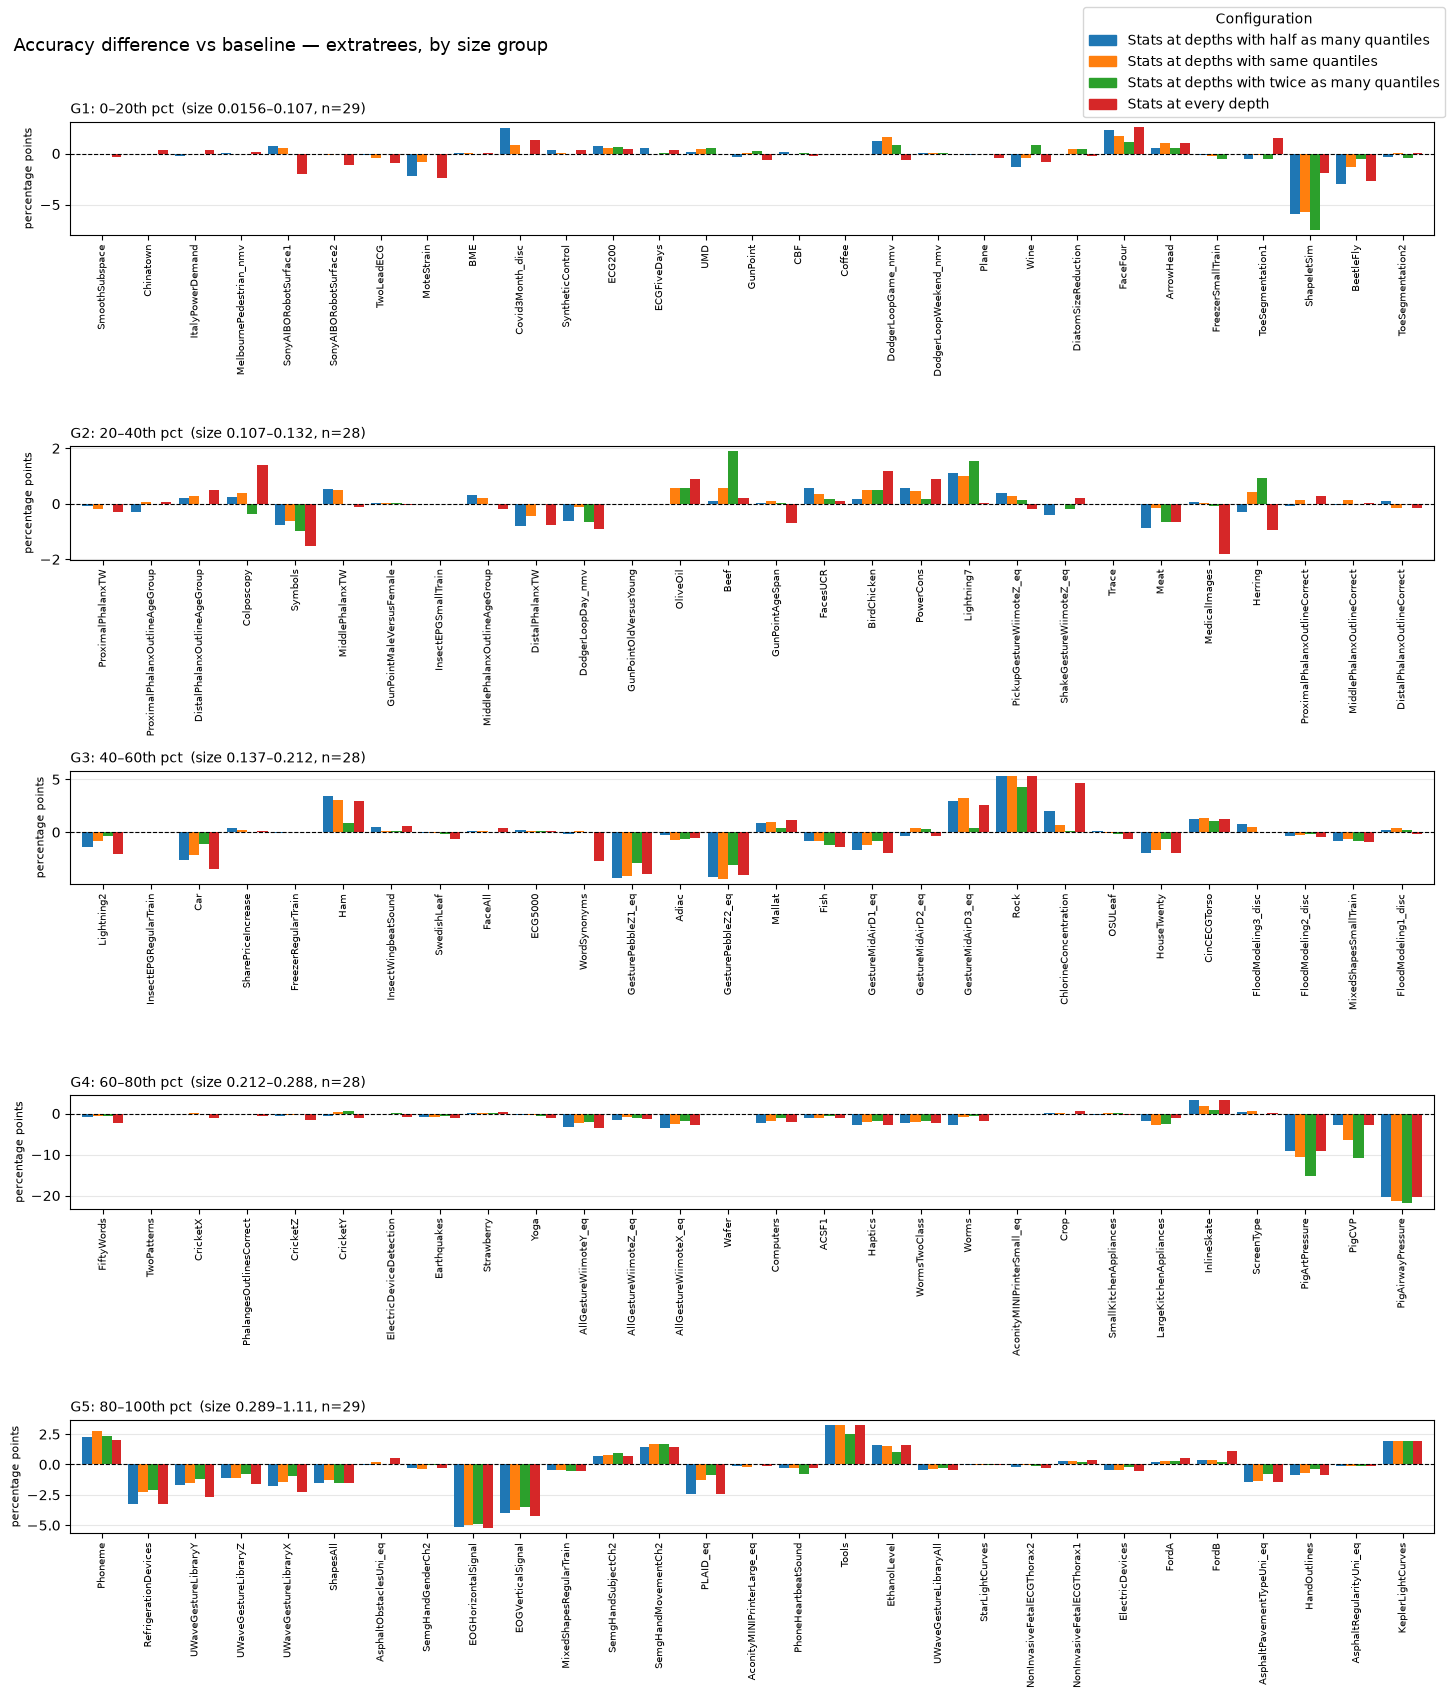

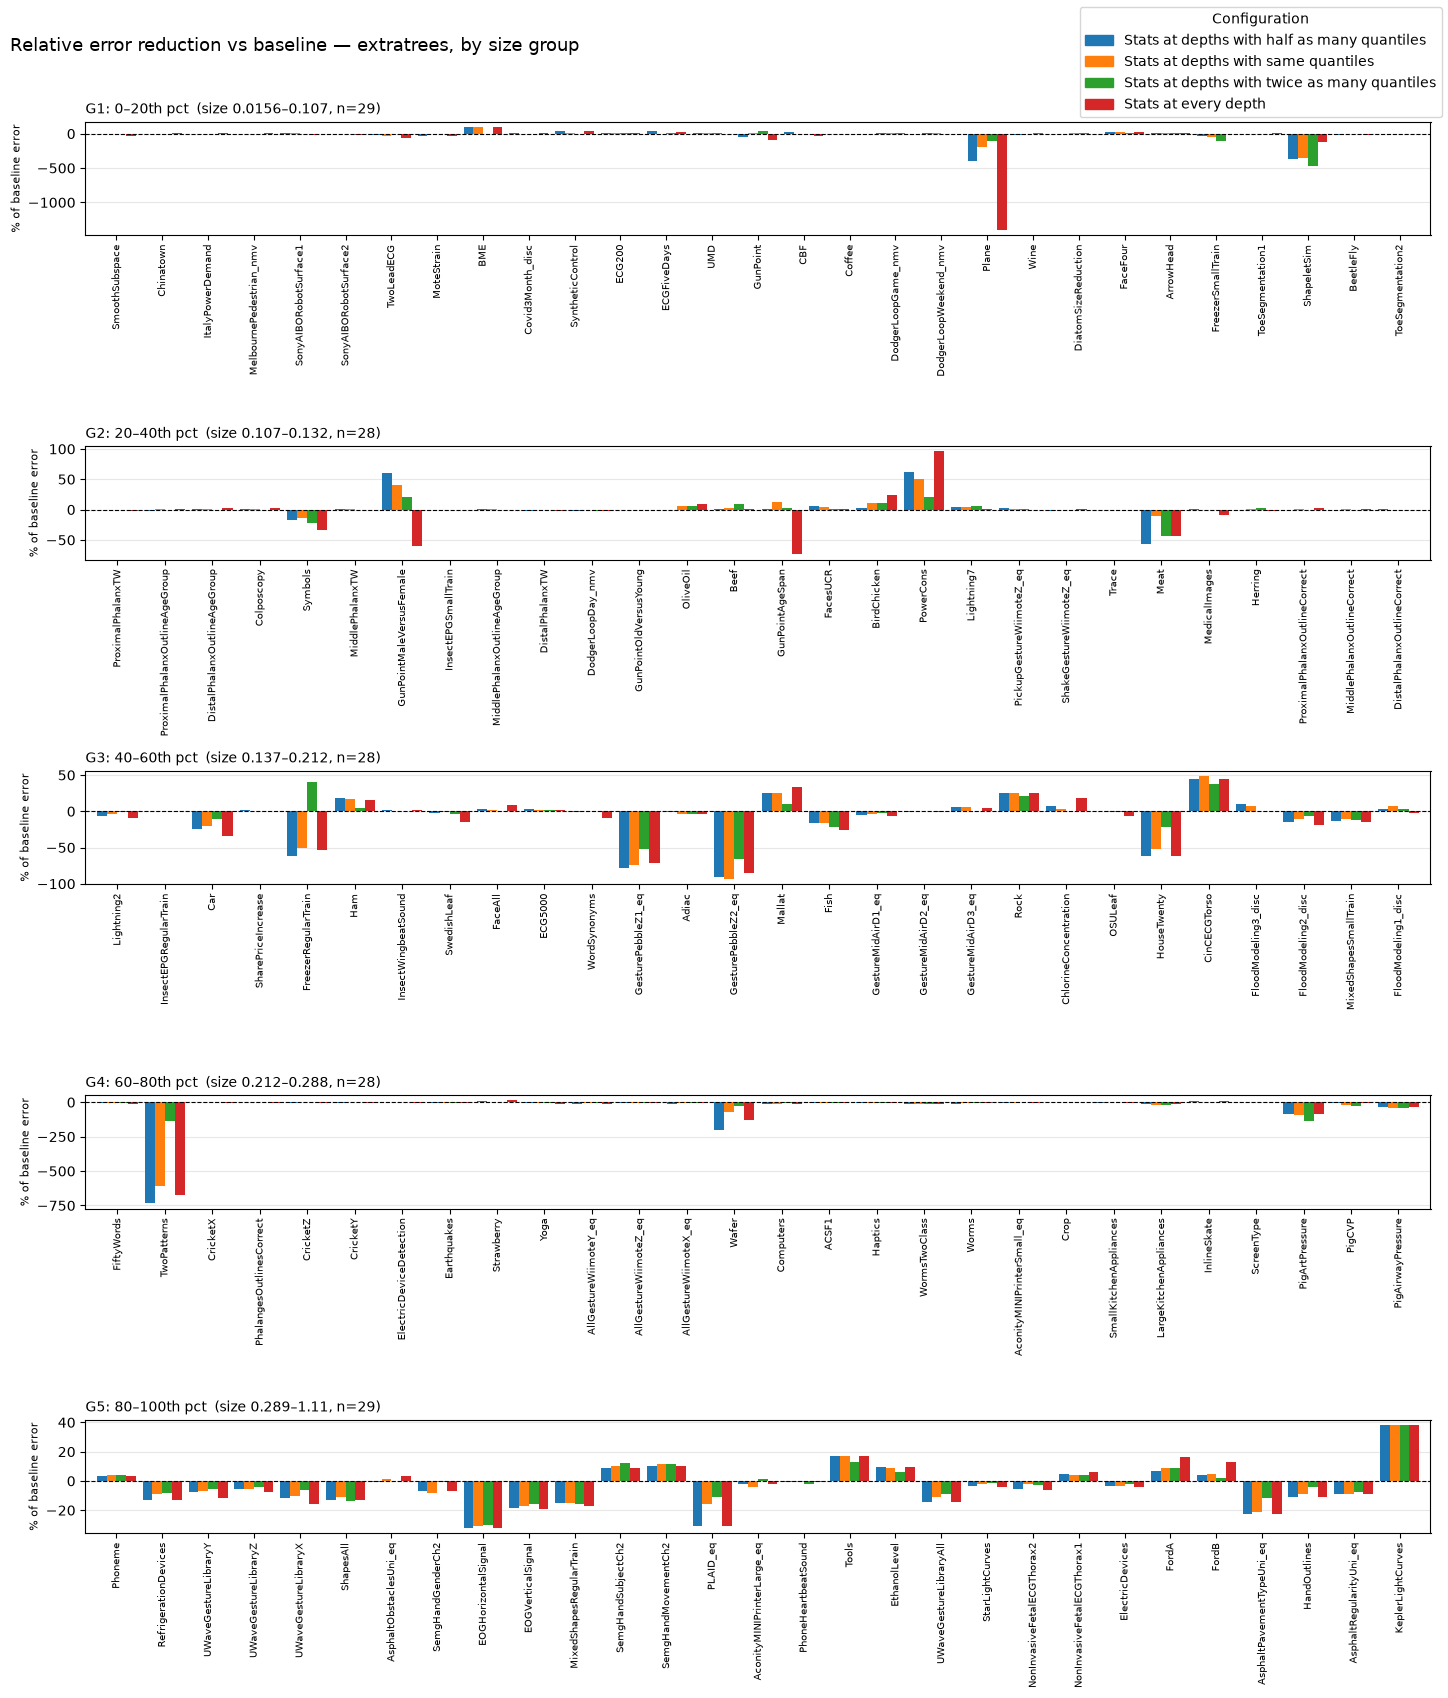

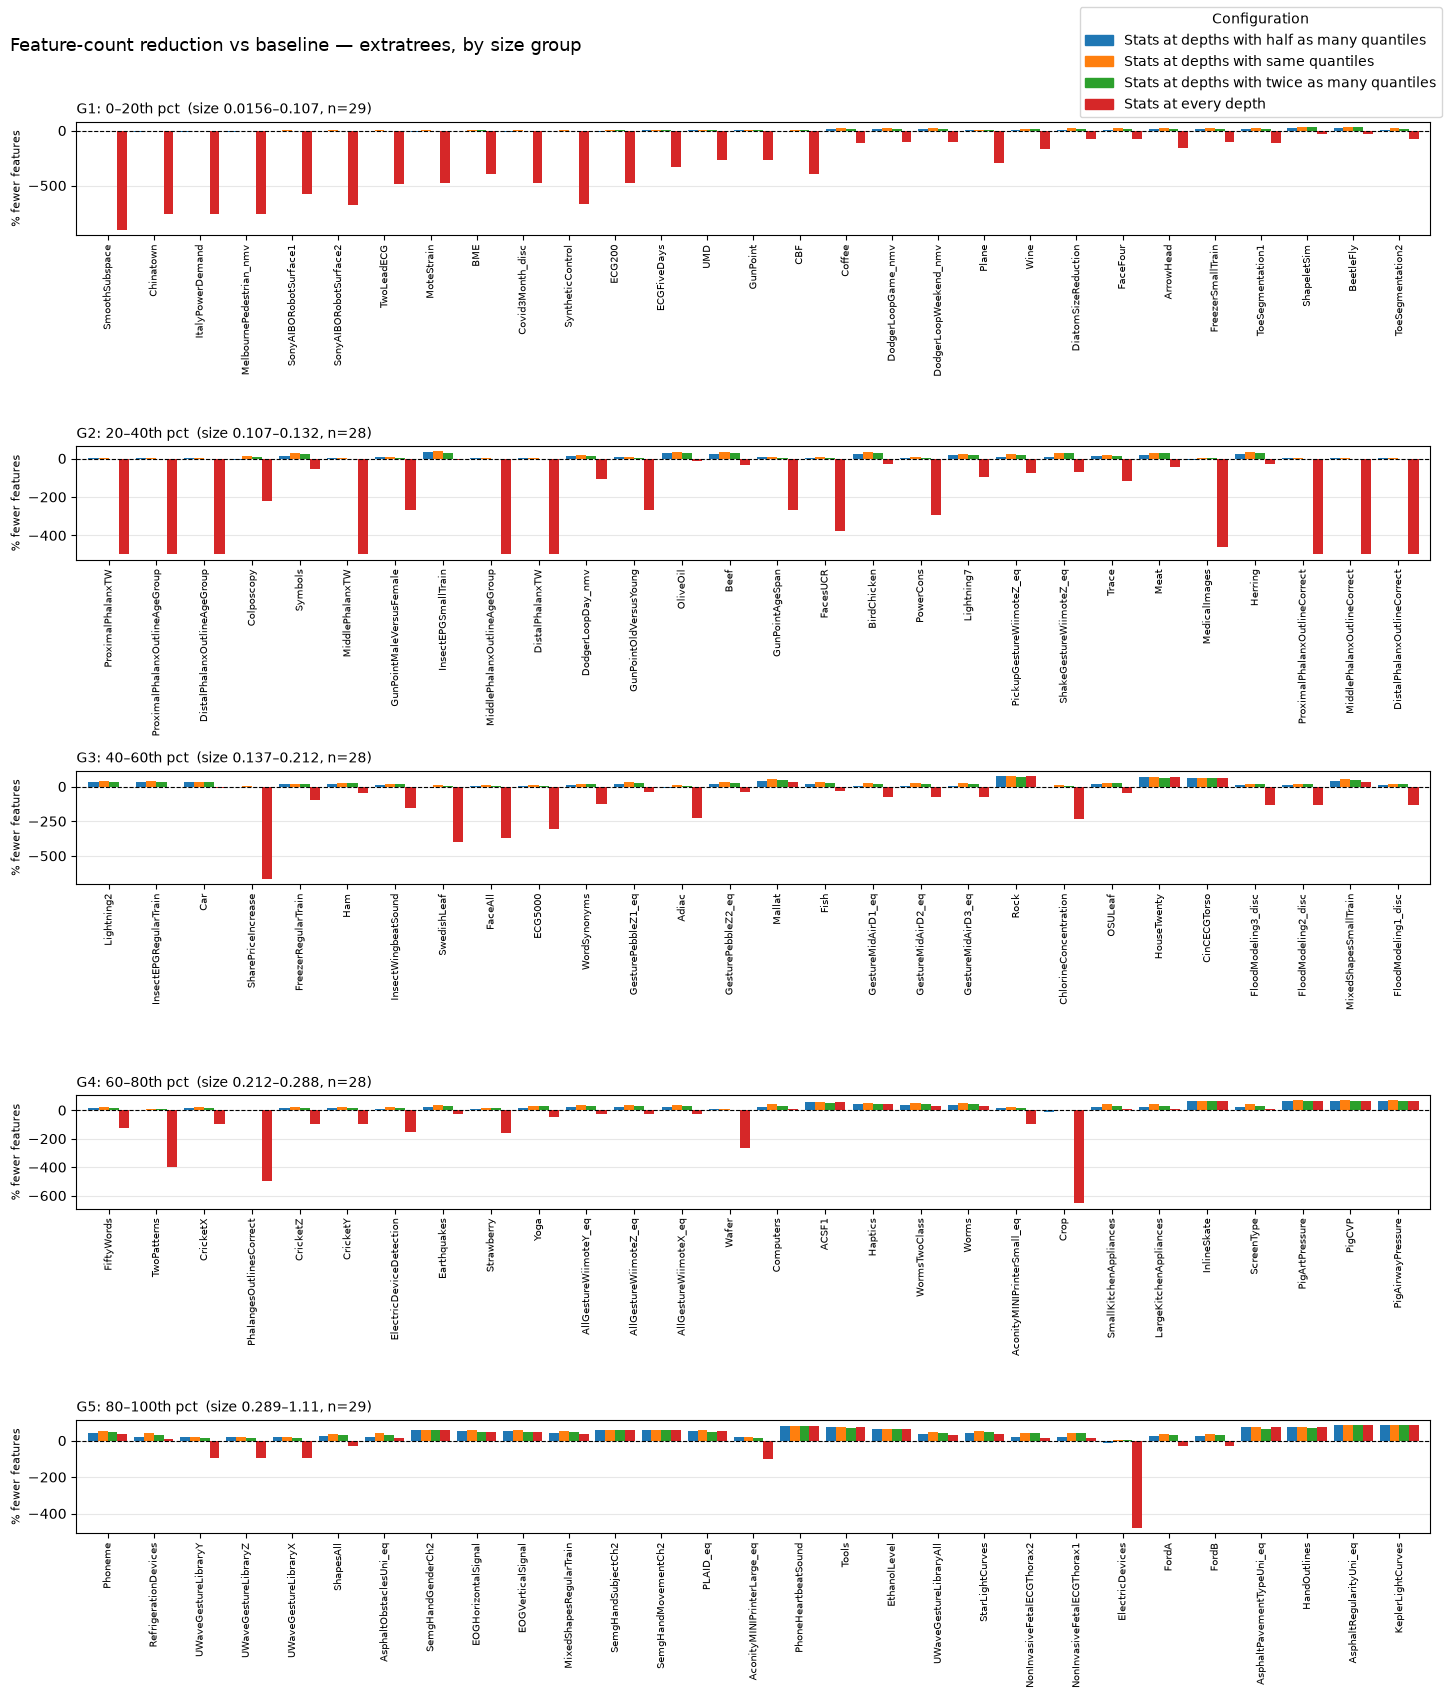

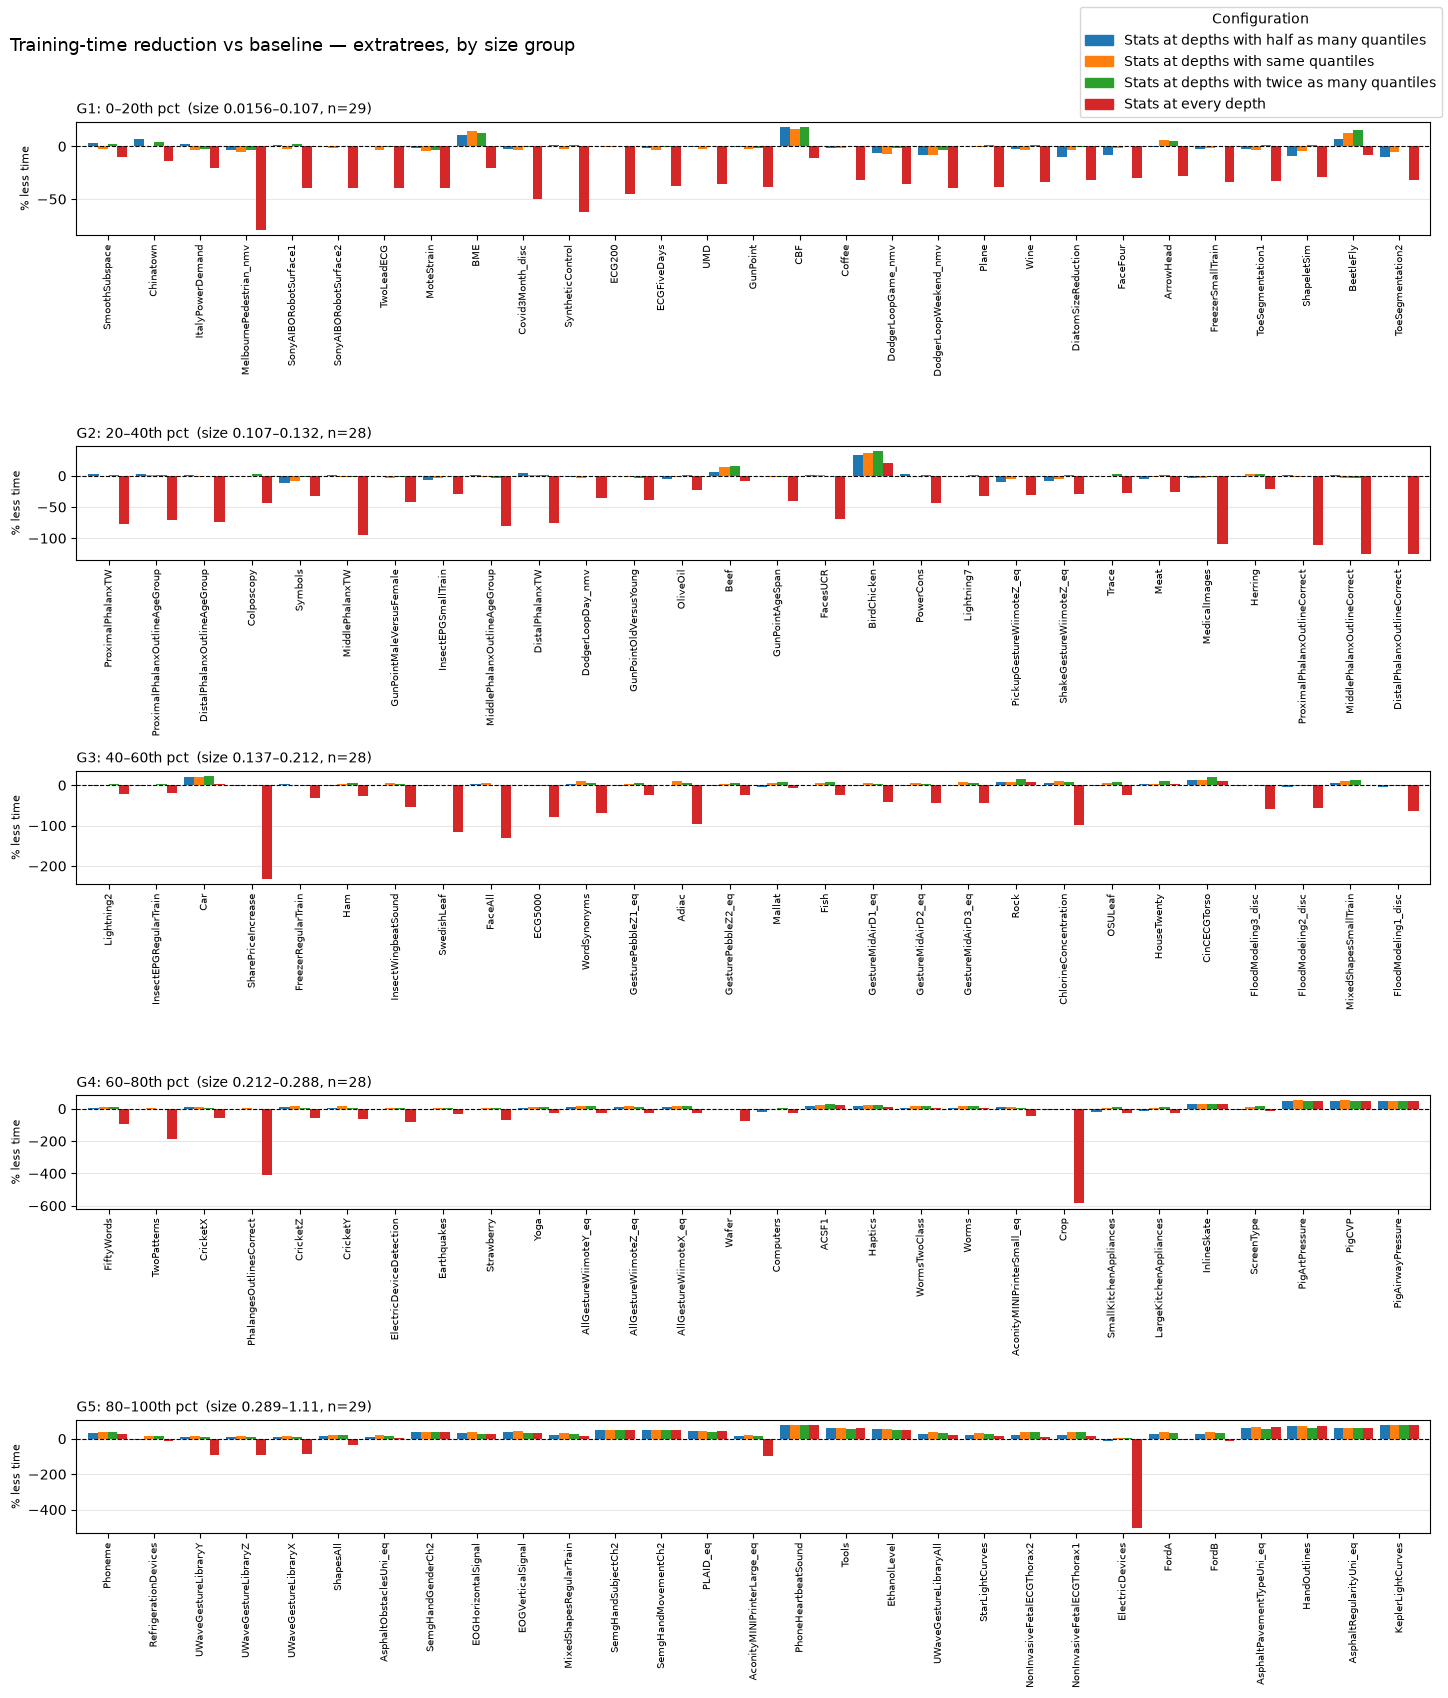

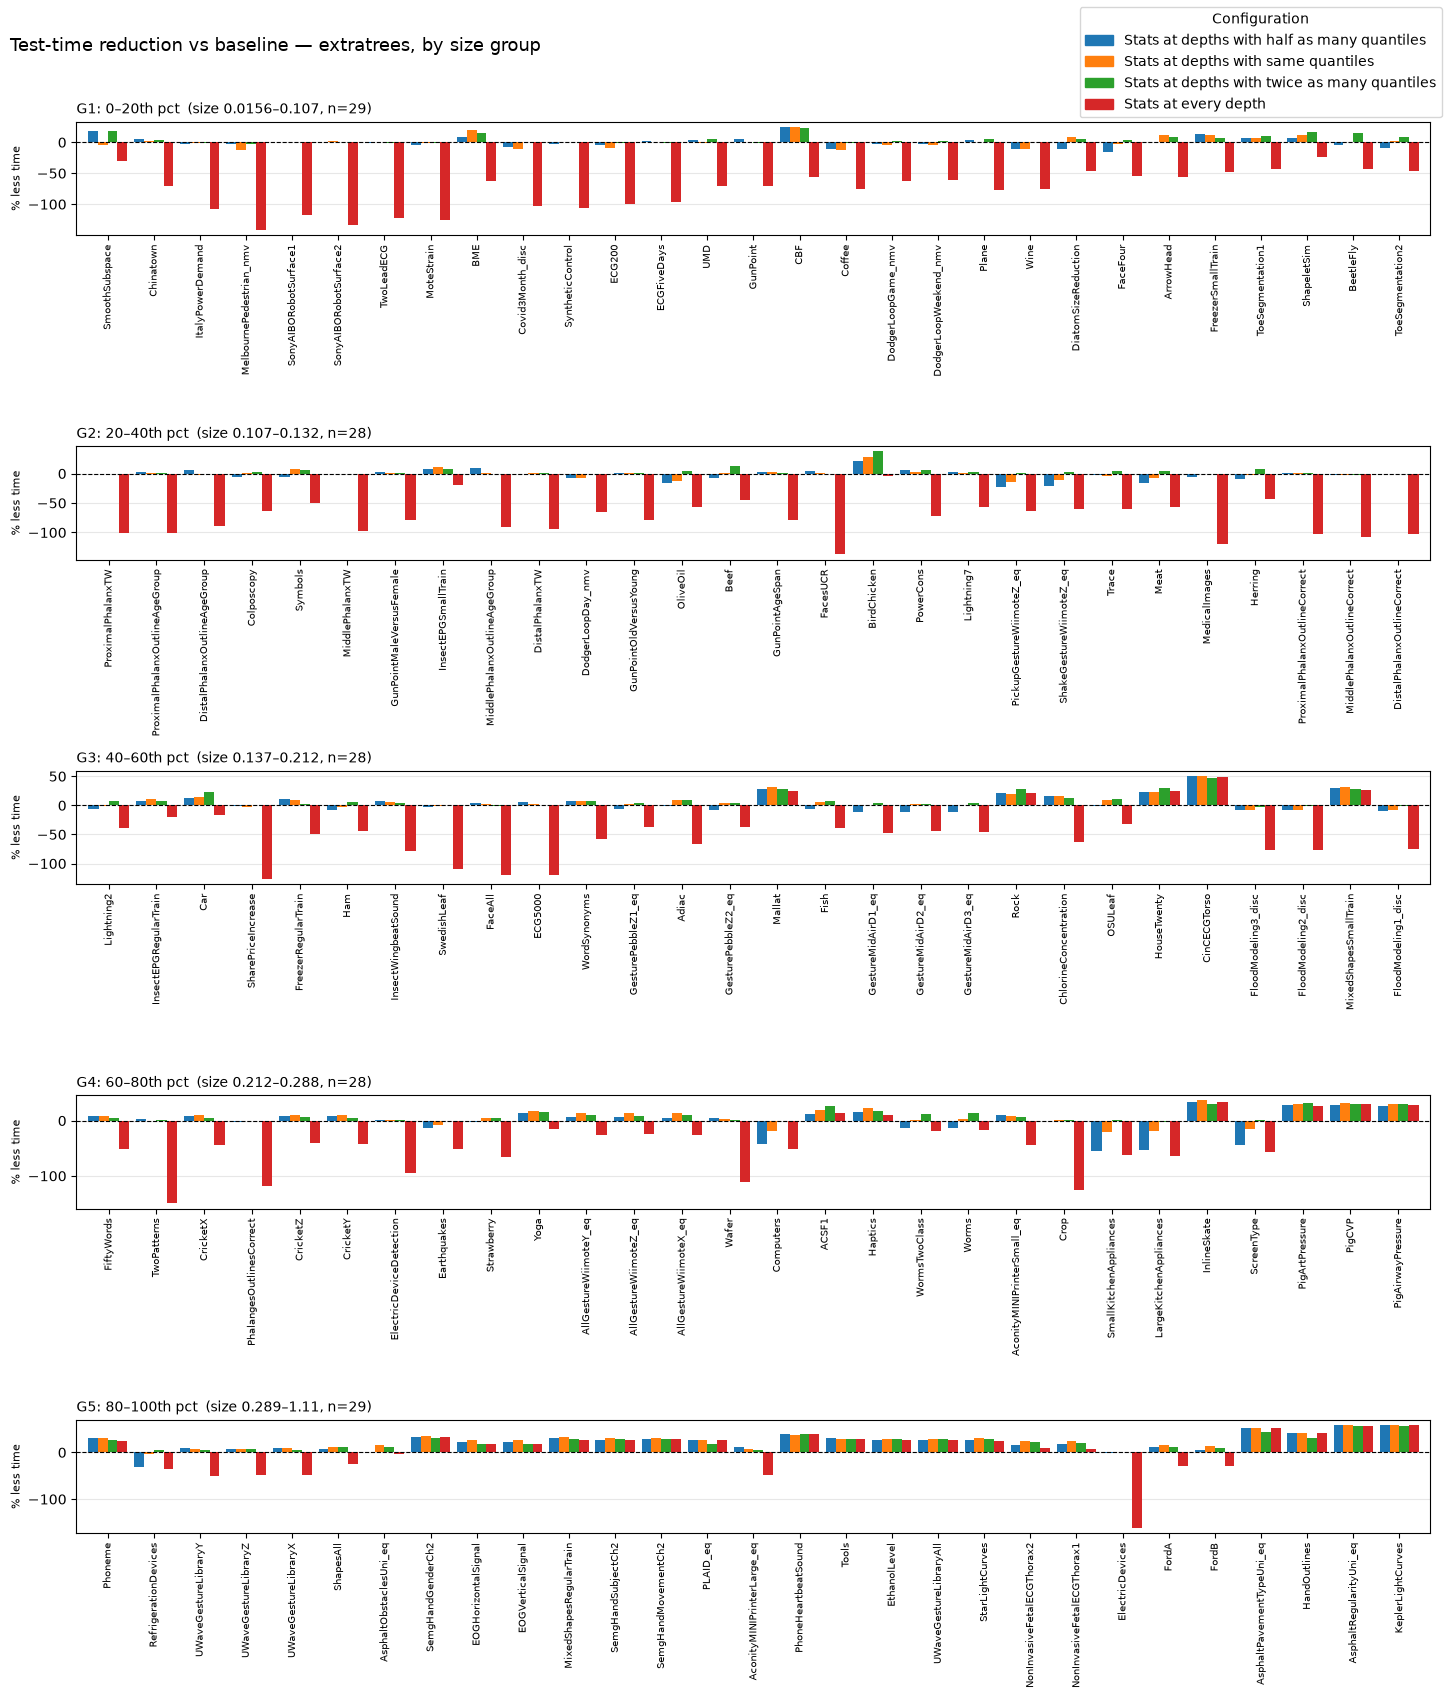

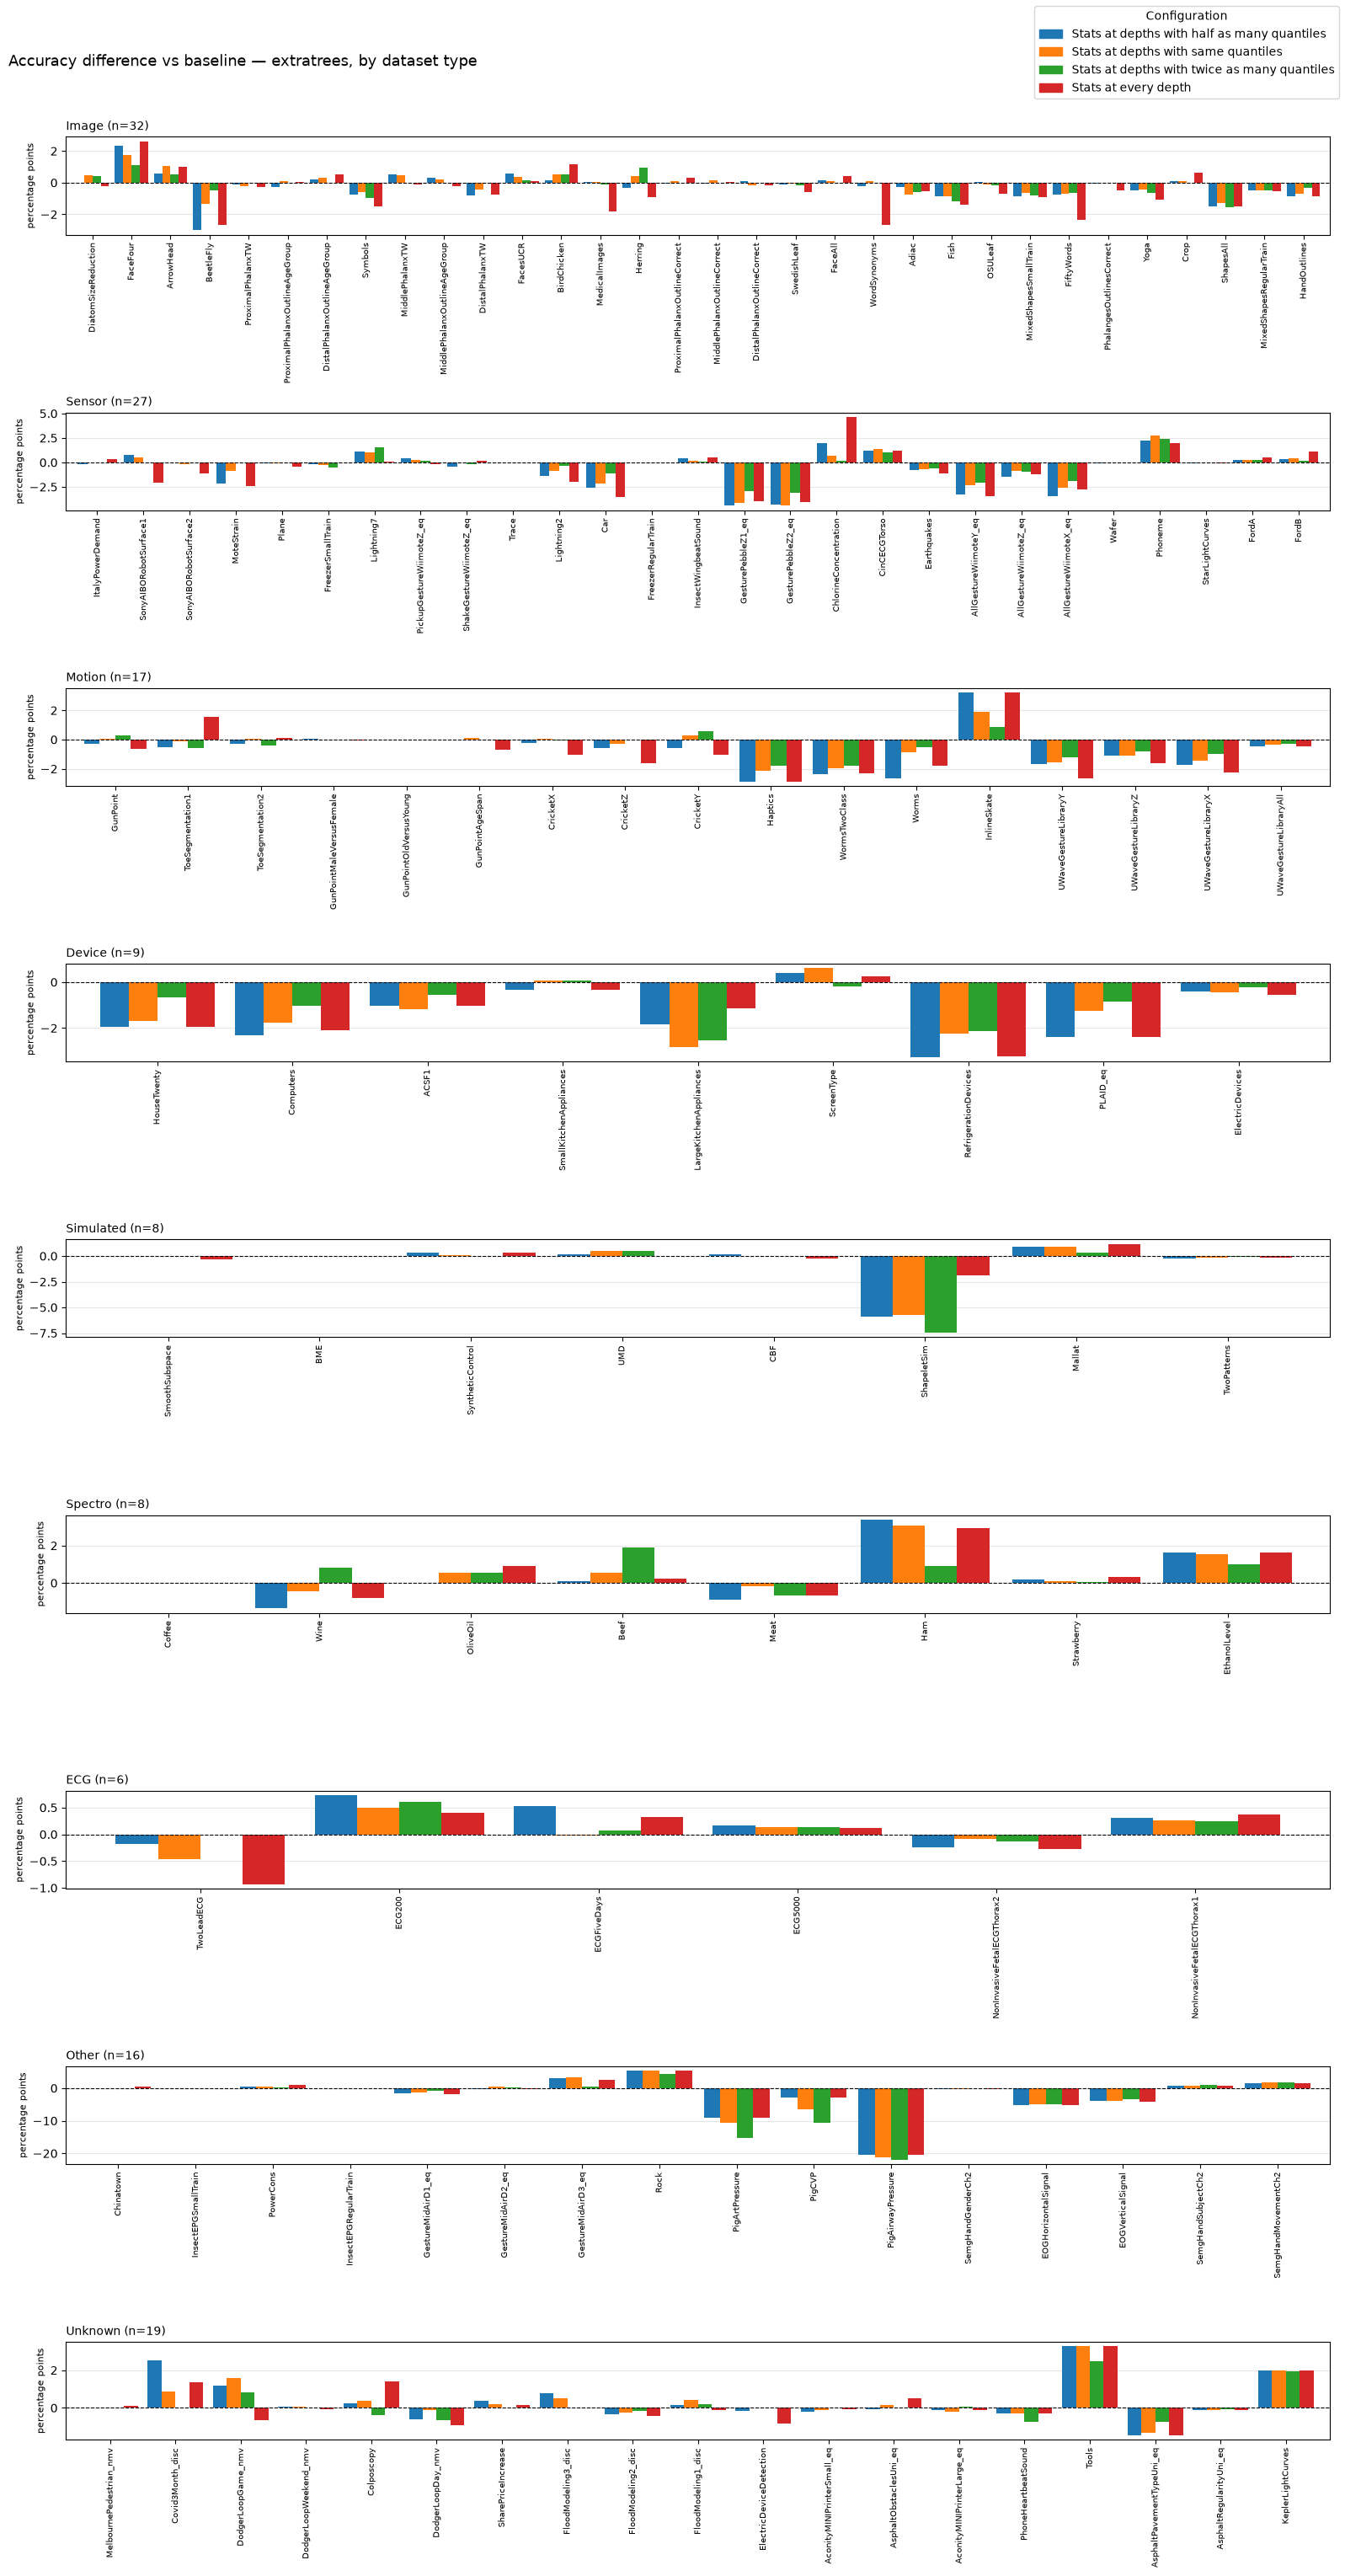

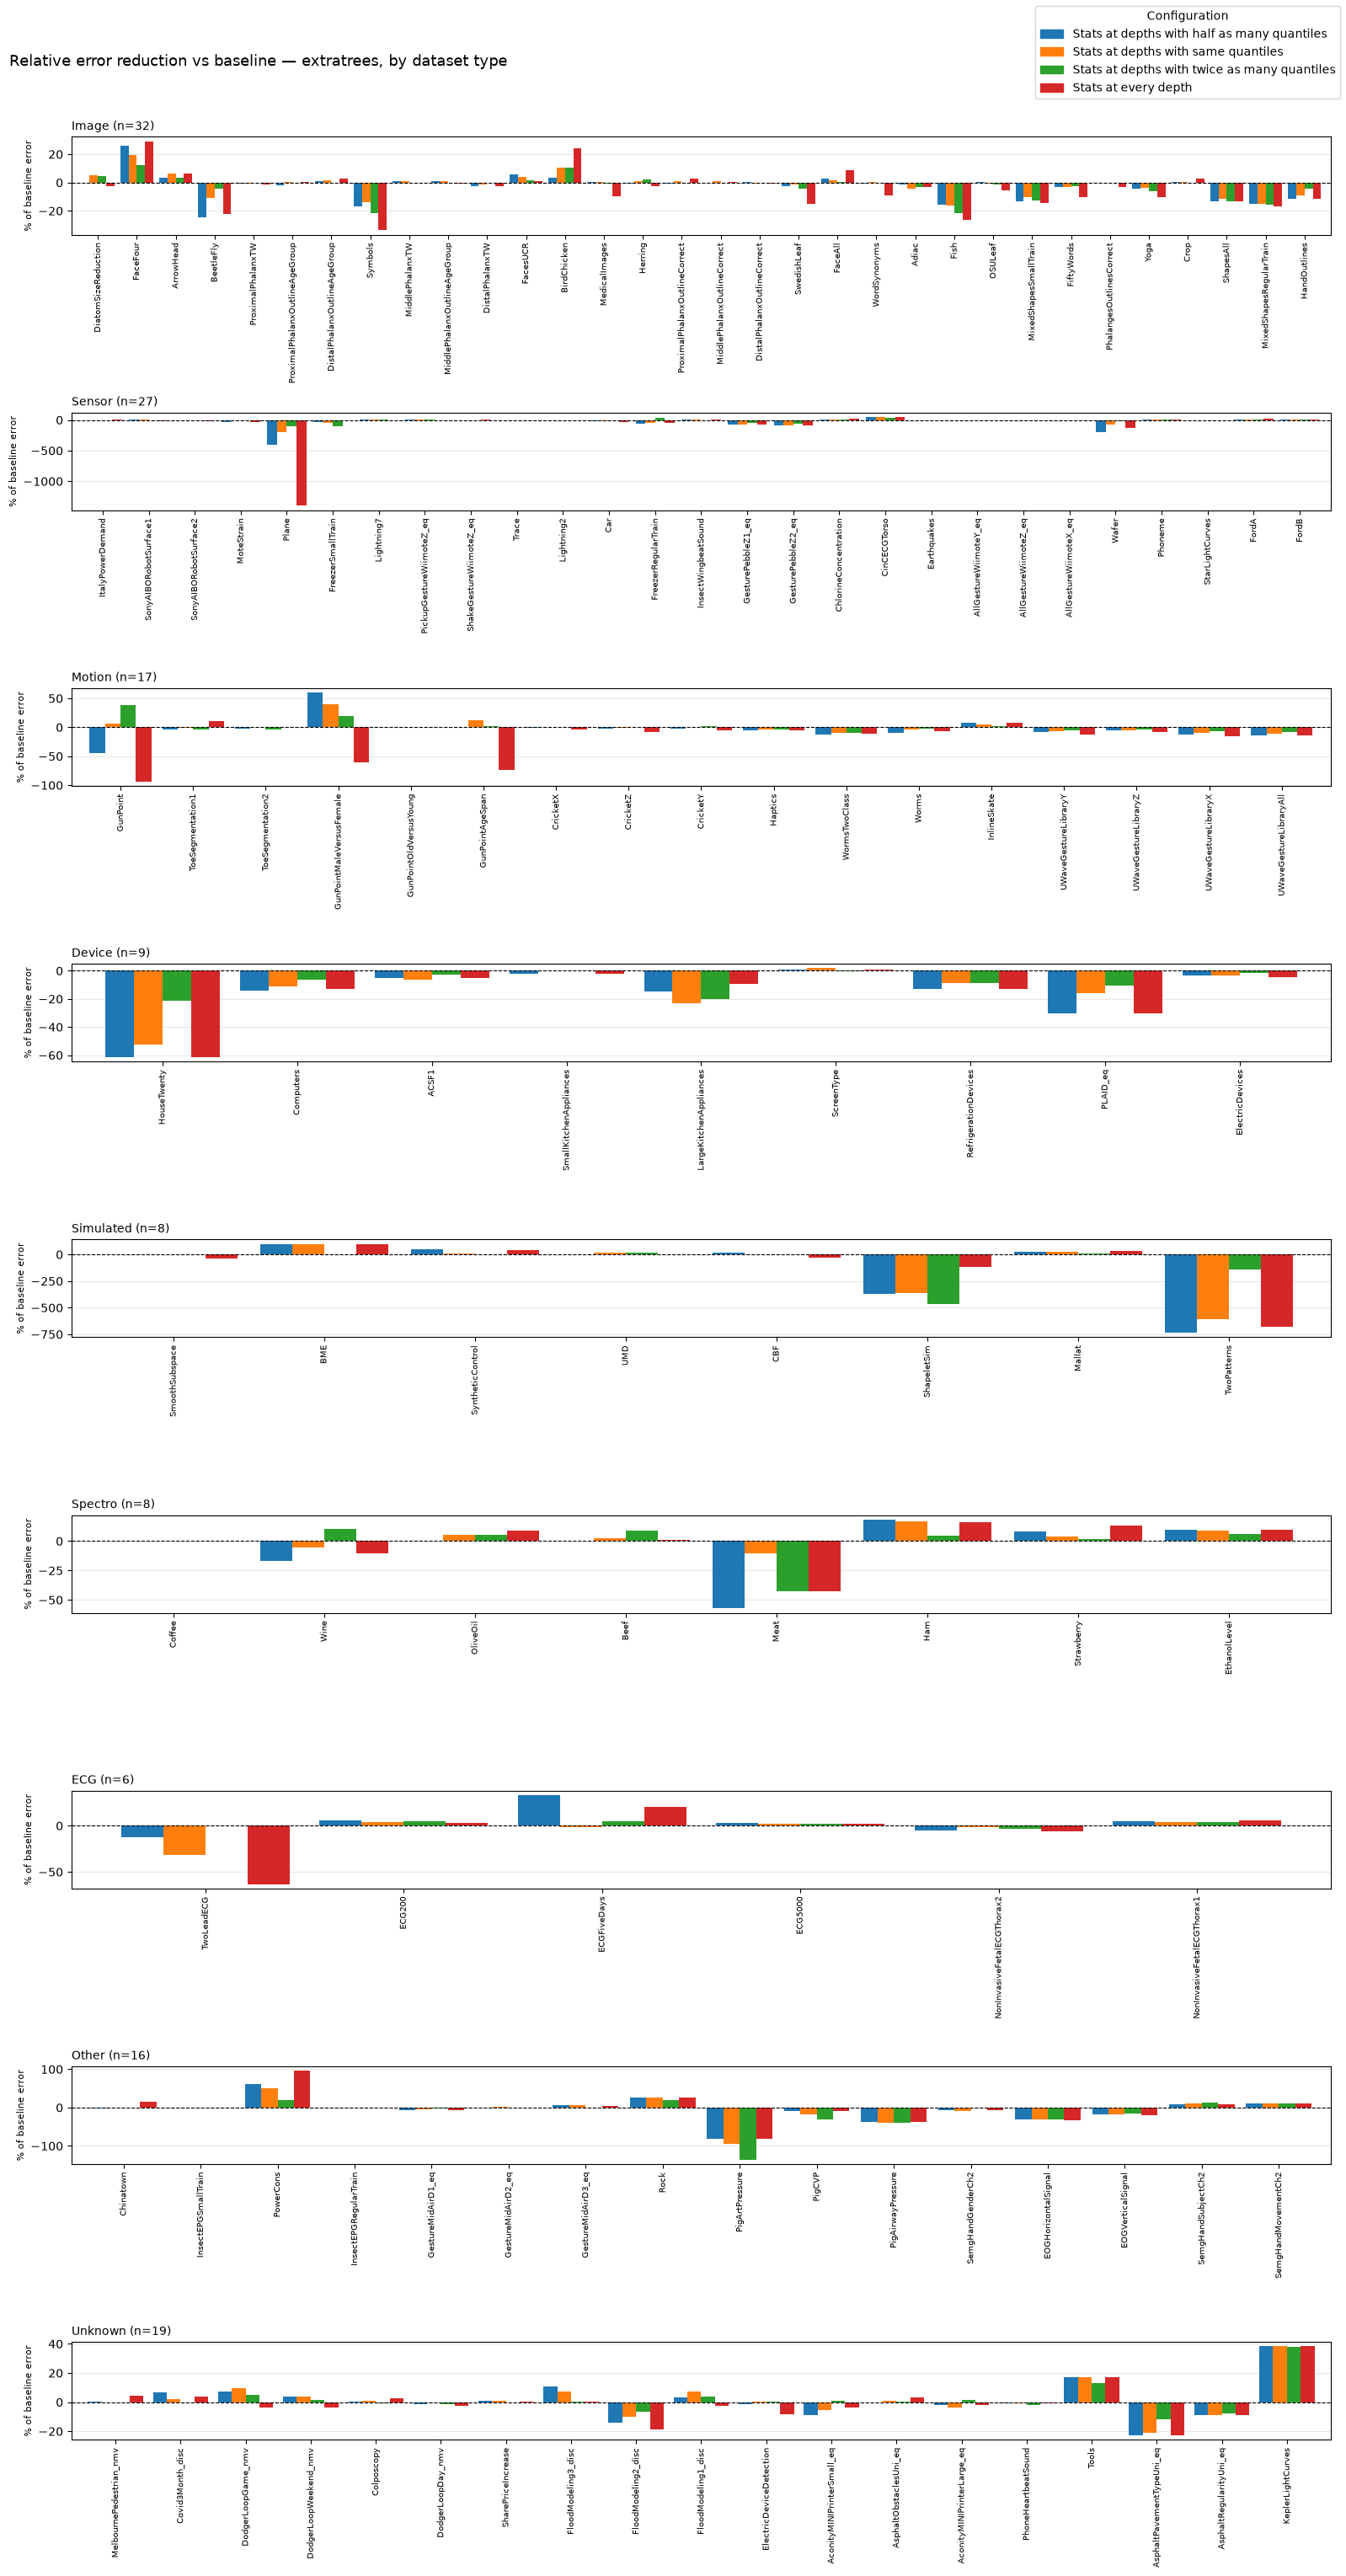

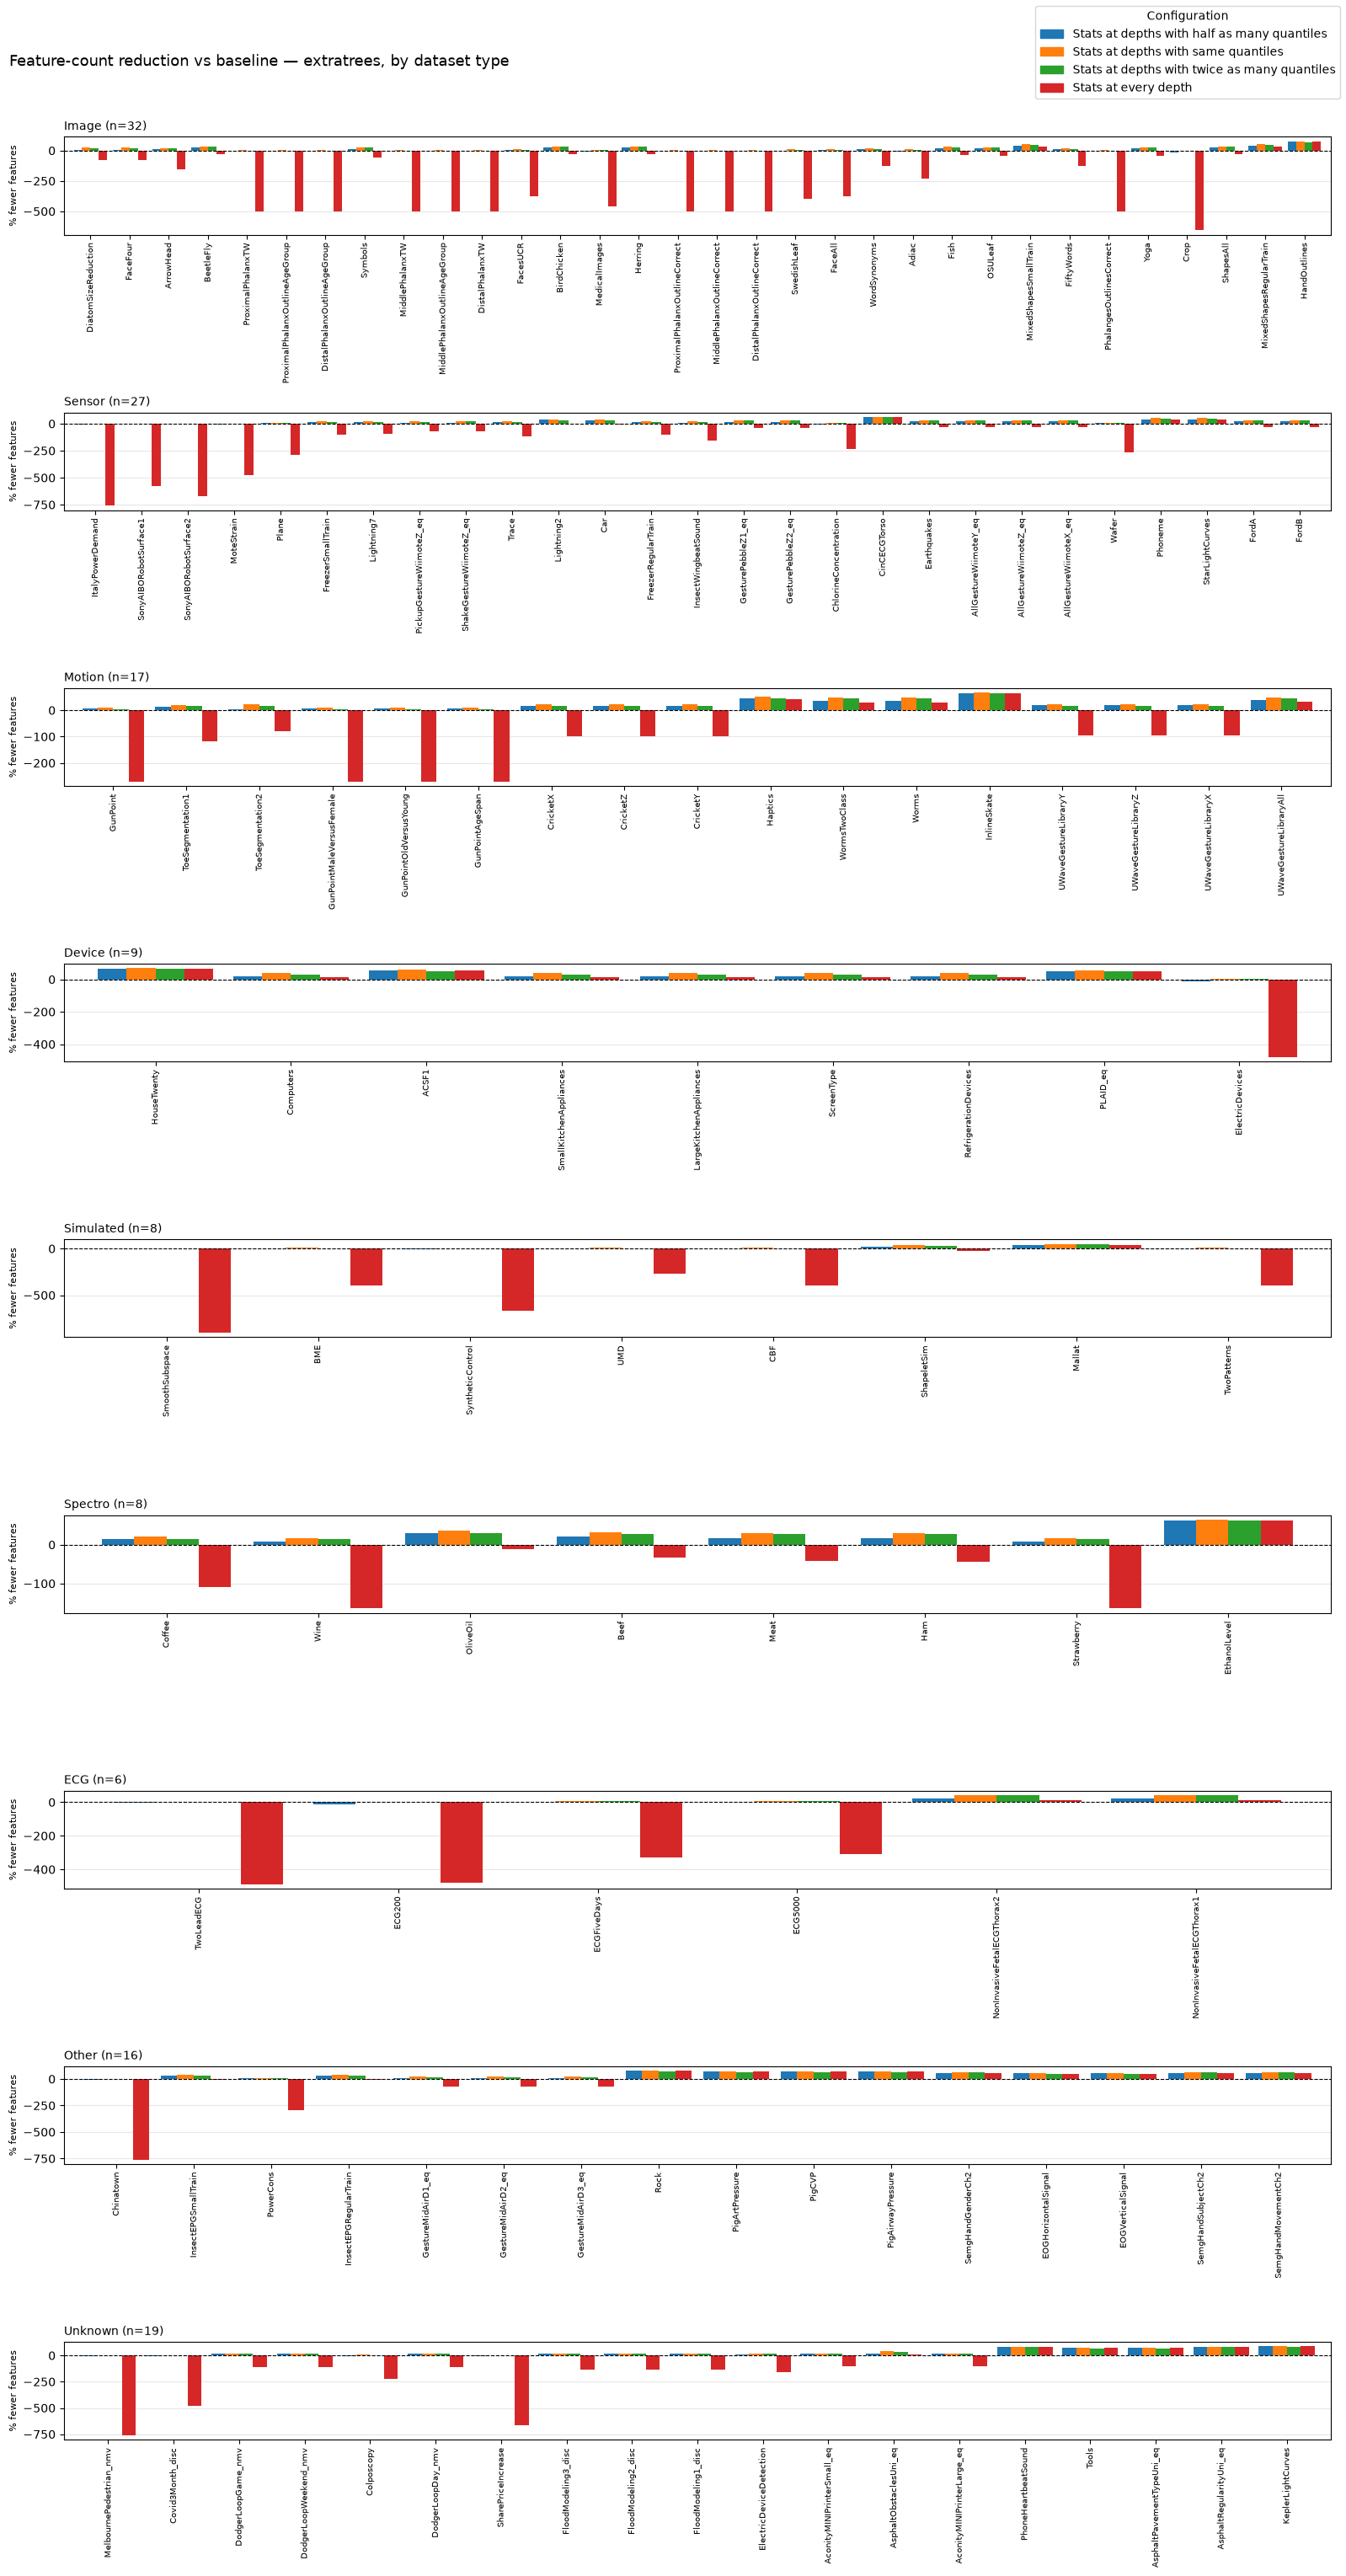

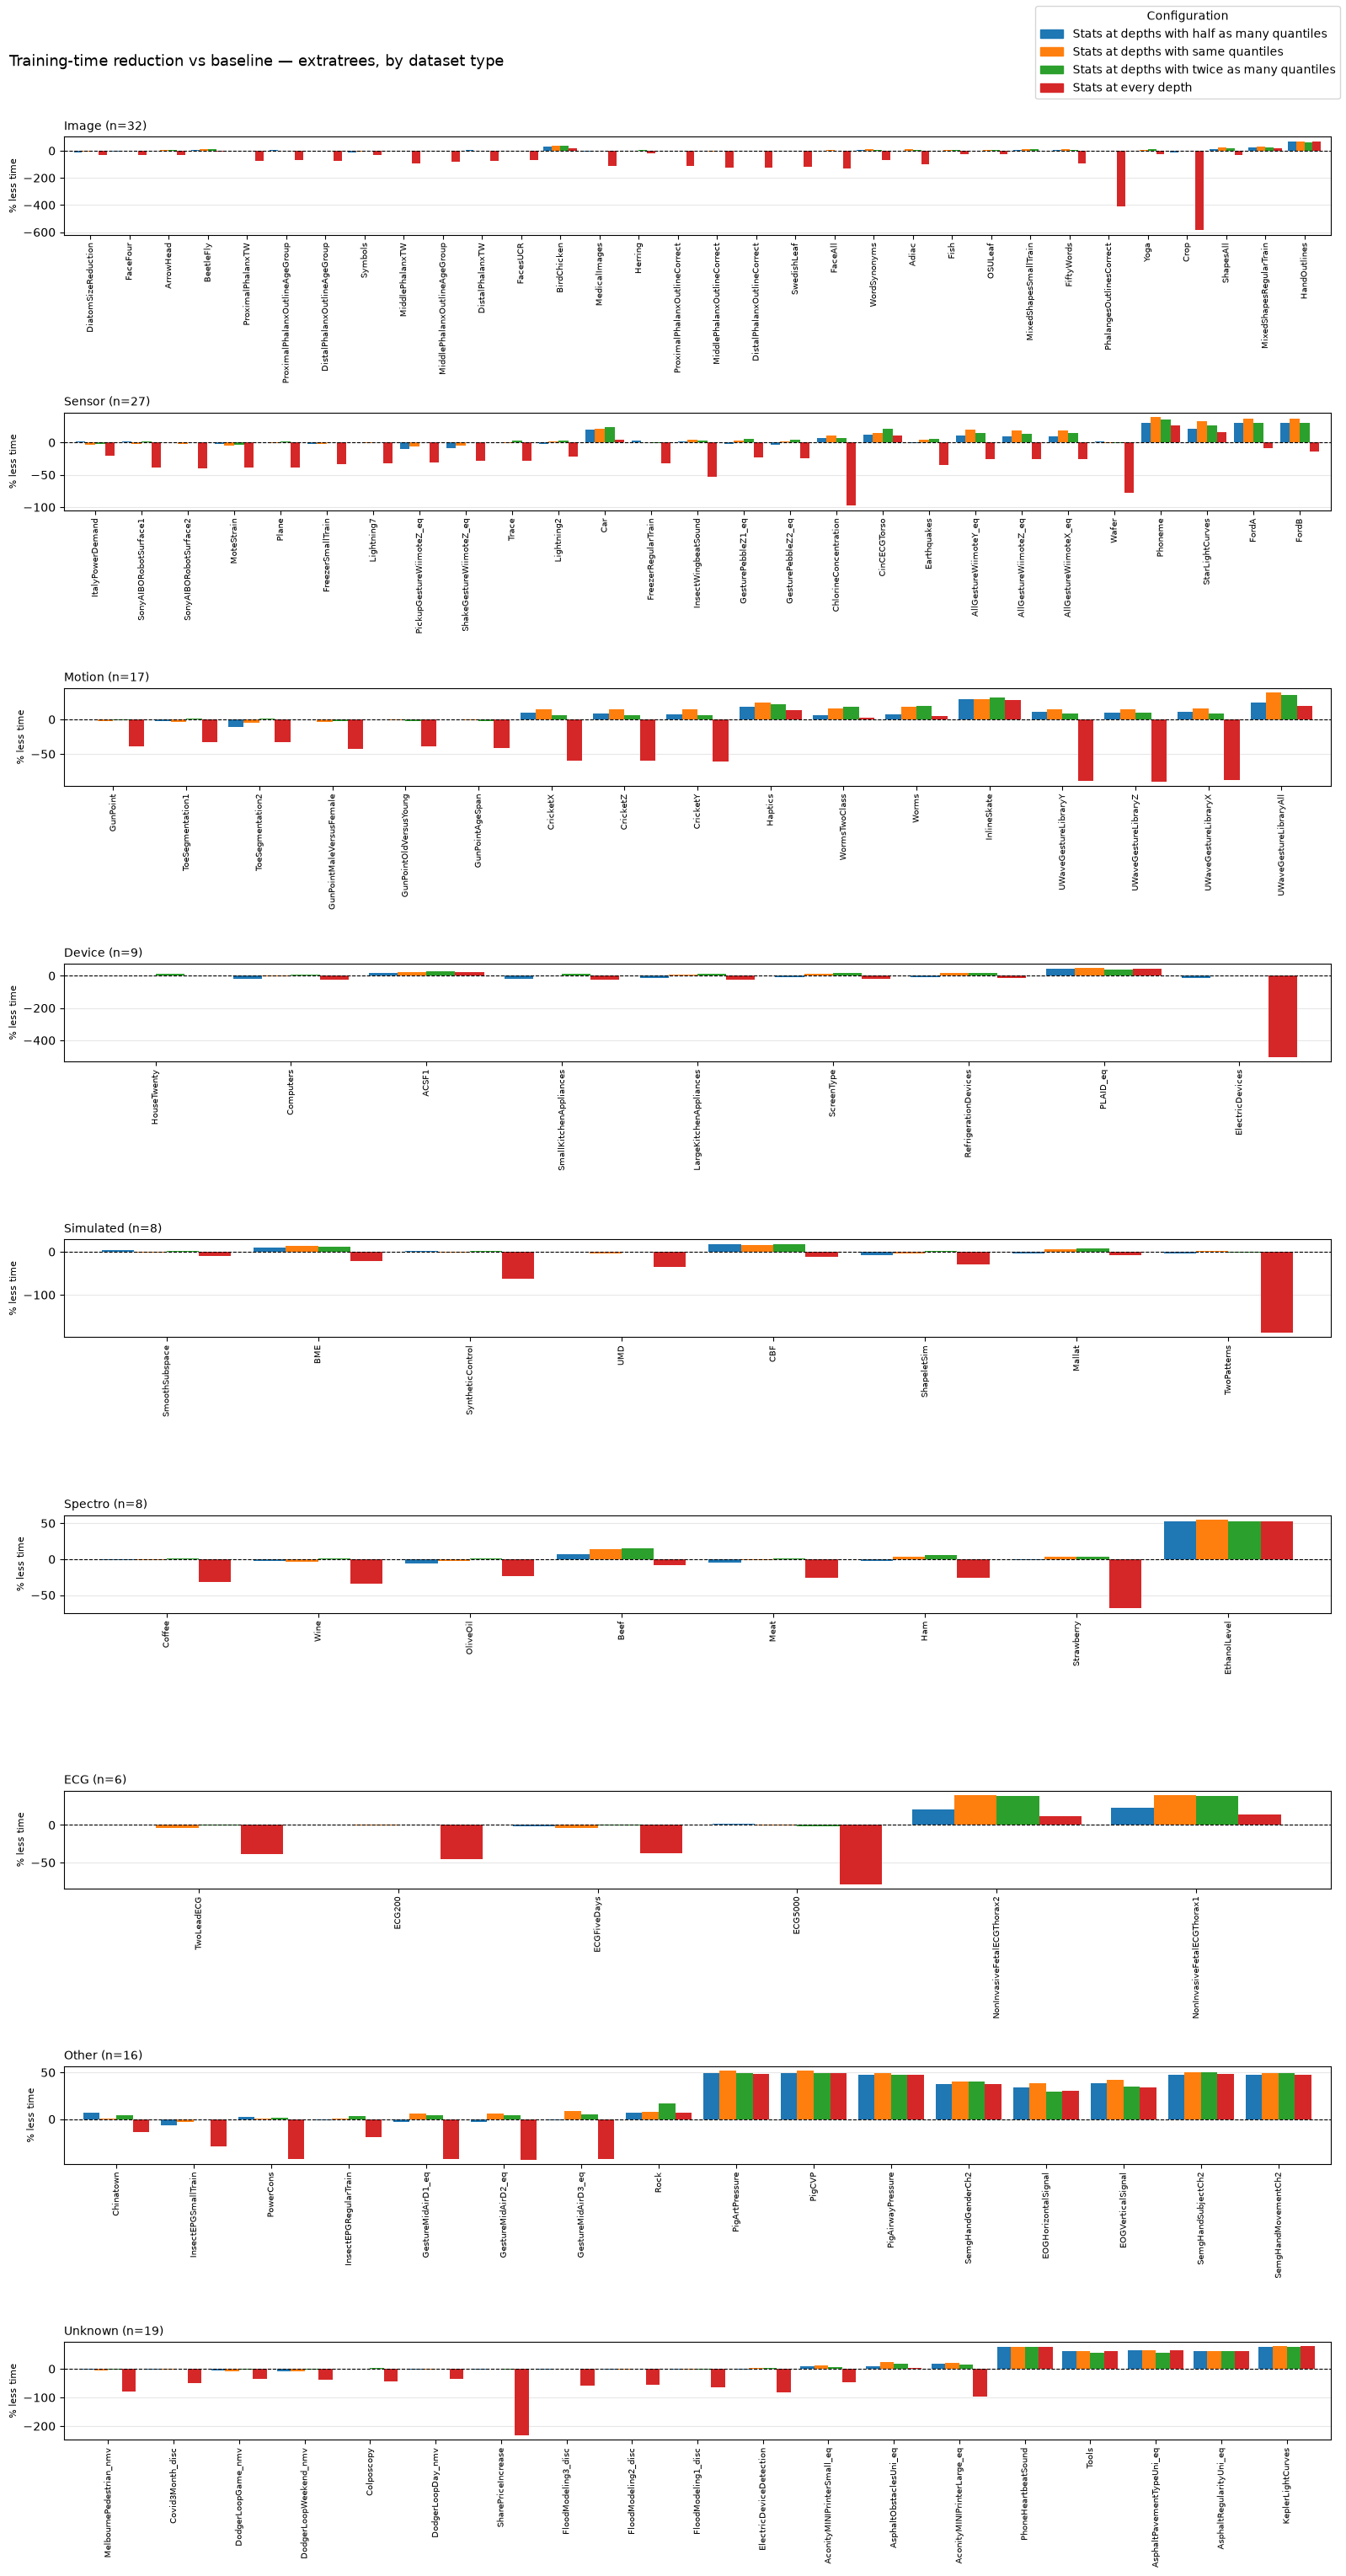

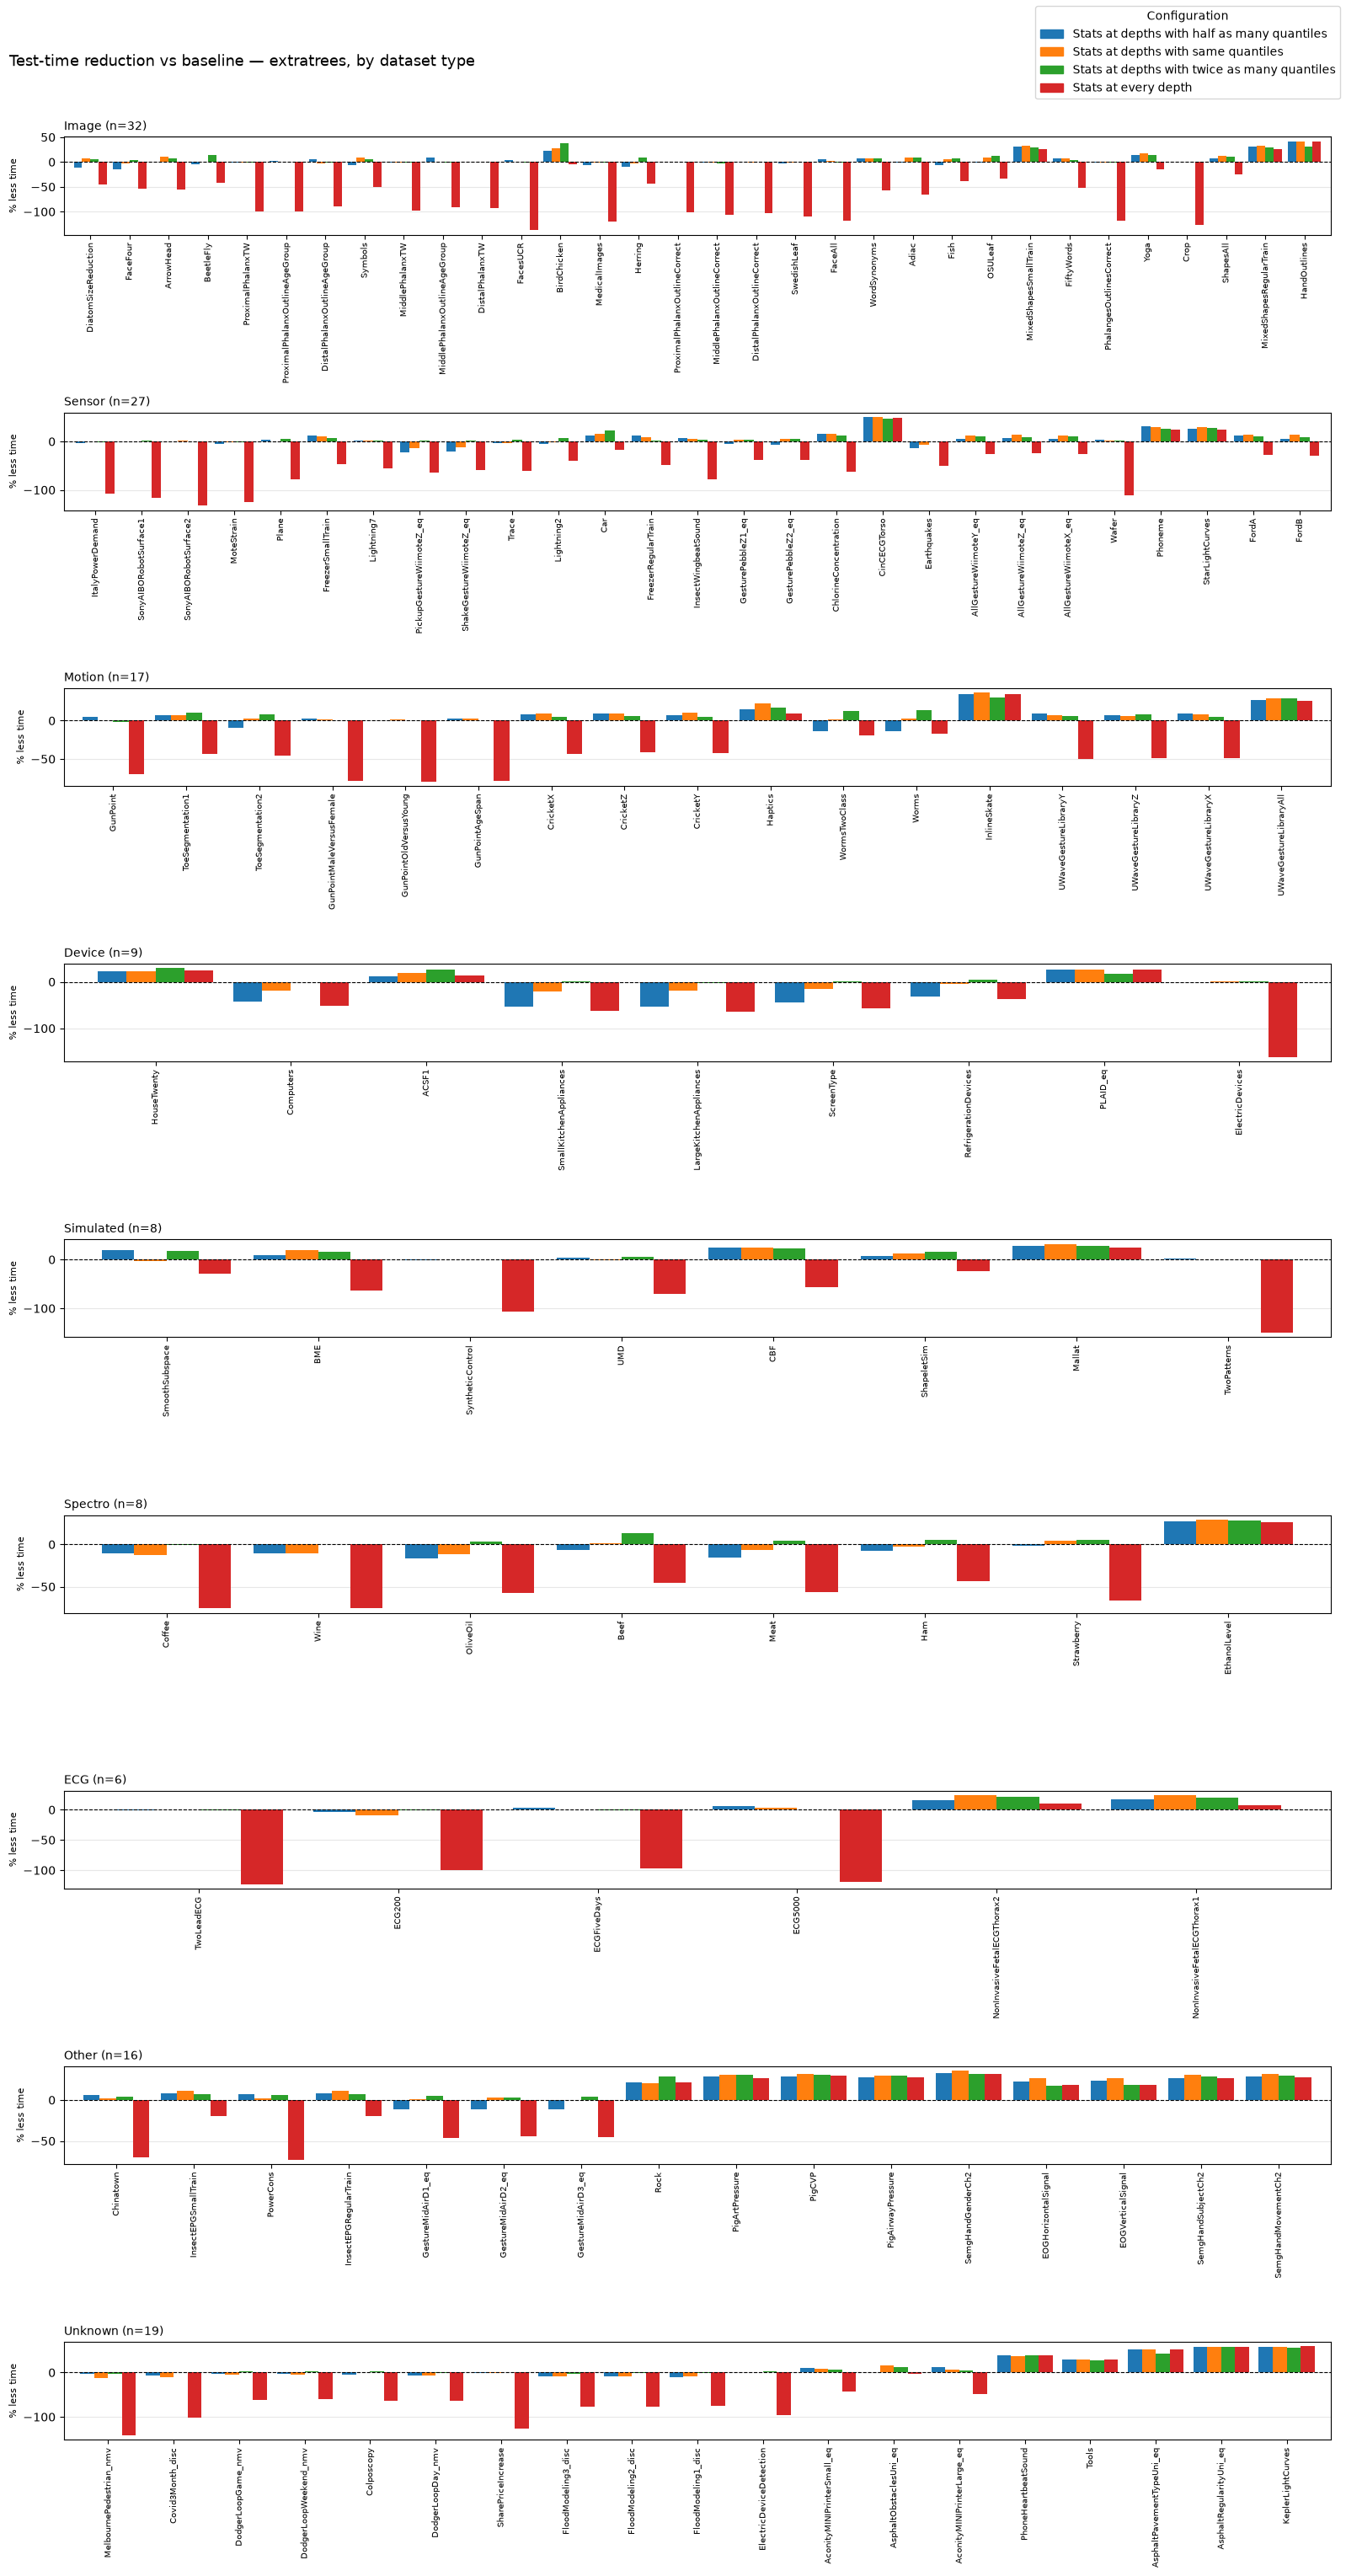

In [12]:
BAR_METRICS = {
    "acc_diff_pp": ("Accuracy difference vs baseline", "percentage points"),
    "error_reduction_pct": ("Relative error reduction vs baseline", "% of baseline error"),
    "feature_reduction_pct": ("Feature-count reduction vs baseline", "% fewer features"),
    "train_time_reduction_pct": ("Training-time reduction vs baseline", "% less time"),
    "test_time_reduction_pct": ("Test-time reduction vs baseline", "% less time"),
}

def plot_grouped_bars(metric, title, ylabel, grouping, col, order):
    for clf in classifiers:
        sub = cmp[cmp["classifier"] == clf]
        present = [name for name in order if (sub[col] == name).any()]
        if not present:
            continue
        widest = max((sub[col] == name).sum() // len(COMPARE_CONFIGS) for name in present)
        fig, axes = plt.subplots(len(present), 1, figsize=(max(14, 0.5 * widest), 3.4 * len(present)), squeeze=False)
        for ax, group_name in zip(axes[:, 0], present):
            g = sub[sub[col] == group_name]
            wide = g.pivot(index="dataset", columns="configuration", values=metric)
            wide = wide.loc[dataset_size.reindex(wide.index).sort_values().index, COMPARE_CONFIGS]
            wide.plot.bar(ax=ax, width=0.85, legend=False, color=[CONFIG_COLORS[c] for c in COMPARE_CONFIGS])
            ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
            ax.set_title(group_name, loc="left", fontsize=10)
            ax.set_xlabel("")
            ax.set_ylabel(ylabel, fontsize=8)
            ax.tick_params(axis="x", labelsize=7, rotation=90)
            ax.grid(axis="y", alpha=0.3)
            ax.set_axisbelow(True)
        fig.legend(handles=[Patch(color=CONFIG_COLORS[c], label=c) for c in COMPARE_CONFIGS],
                   title="Configuration", loc="upper right")
        fig.suptitle(f"{title} — {clf}, by {grouping}", x=0.01, ha="left", fontsize=13)
        fig.tight_layout(rect=(0, 0, 1, 0.97))
        plt.show()

for grouping, (col, order) in GROUPINGS.items():
    for metric, (title, ylabel) in BAR_METRICS.items():
        plot_grouped_bars(metric, title, ylabel, grouping, col, order)

## 8. Statistical significance

### 8a. Critical difference diagrams (across datasets)

Uses the Friedman test followed by Wilcoxon-Holm pairwise tests on the **per-dataset mean accuracies** (Demšar 2006; [hfawaz/cd-diagram](https://github.com/hfawaz/cd-diagram)). Methods joined by a thick bar are **not** significantly different. The first cell draws one diagram per classifier and per experiment group in `EXPERIMENT_GROUPS` (the baseline is always included); the second draws one per dataset-size group and one per dataset type.

Requires `cd_diagram.py`: the repo's `main.py`, renamed and with four small patches (no forced `agg` backend, no `exit()`, an output-file argument, and the example code guarded by `if __name__ == "__main__"`). The Friedman test needs at least 3 methods in a diagram, i.e. the baseline plus at least 2 configurations.

A significant rank difference means the configuration is *consistently* better or worse across datasets, not that the difference is large. Read it together with the accuracy differences in section 6. Groups contain only a few dozen datasets (or fewer), so "no significant difference" in a group mostly means low power, not evidence of equivalence.

<StringArray>
['Baseline (Quant Features)', 'Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', 'Stats at depths with twice as many quantiles', 'Stats at every depth']
Length: 5, dtype: str
Baseline (Quant Features)                       53.0
Stats at depths with half as many quantiles     18.0
Stats at depths with same quantiles             15.0
Stats at depths with twice as many quantiles    14.0
Stats at every depth                            23.0
dtype: float64
Stats at every depth                            3.492958
Stats at depths with half as many quantiles     3.225352
Stats at depths with twice as many quantiles    2.890845
Baseline (Quant Features)                       2.711268
Stats at depths with same quantiles             2.679577
dtype: float64
('Stats at depths with same quantiles', 'Stats at every depth', np.float64(7.185469928552214e-05), True)
('Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', np.f

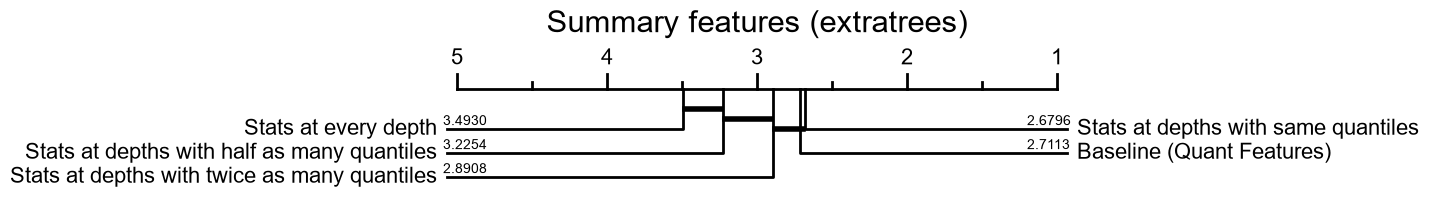

In [13]:
import re
import sys

CD_DIAGRAM_DIR = Path("..")      # folder that contains cd_diagram.py
sys.path.insert(0, str(CD_DIAGRAM_DIR.resolve()))
from cd_diagram import draw_cd_diagram

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
CD_ALPHA = 0.05

EXPERIMENT_GROUPS = {
    "Summary features": COMPARE_CONFIGS,
}

for clf in classifiers:
    for group_name, group_configs in EXPERIMENT_GROUPS.items():
        names = [BASELINE] + [c for c in group_configs if c != BASELINE]
        if len(names) < 3:
            print(f"Skipping '{group_name}' ({clf}): the Friedman test needs at least 3 methods, got {len(names)}.")
            continue
        slug = re.sub(r"\W+", "_", group_name)
        df_perf = (
            table[(table["classifier"] == clf) & table["configuration"].isin(names)]
            .rename(columns={"configuration": "classifier_name", "dataset": "dataset_name"})
            [["classifier_name", "dataset_name", "accuracy"]]
        )
        try:
            draw_cd_diagram(
                df_perf=df_perf, alpha=CD_ALPHA, title=f"{group_name} ({clf})", labels=True,
                filename=FIG_DIR / f"cd_{clf}_{slug}.png",
            )
        except RuntimeError as err:          # Friedman test not significant
            print(f"No diagram for '{group_name}' ({clf}): {err}")

<StringArray>
['Baseline (Quant Features)', 'Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', 'Stats at depths with twice as many quantiles', 'Stats at every depth']
Length: 5, dtype: str
Baseline (Quant Features)                       4.0
Stats at depths with half as many quantiles     6.0
Stats at depths with same quantiles             3.0
Stats at depths with twice as many quantiles    3.0
Stats at every depth                            6.0
dtype: float64
Stats at every depth                            3.258621
Baseline (Quant Features)                       3.051724
Stats at depths with twice as many quantiles    3.000000
Stats at depths with half as many quantiles     2.896552
Stats at depths with same quantiles             2.793103
dtype: float64
('Stats at depths with same quantiles', 'Stats at every depth', np.float64(0.25164427847217485), False)
('Baseline (Quant Features)', 'Stats at depths with twice as many quantiles', np.float64(0.255965

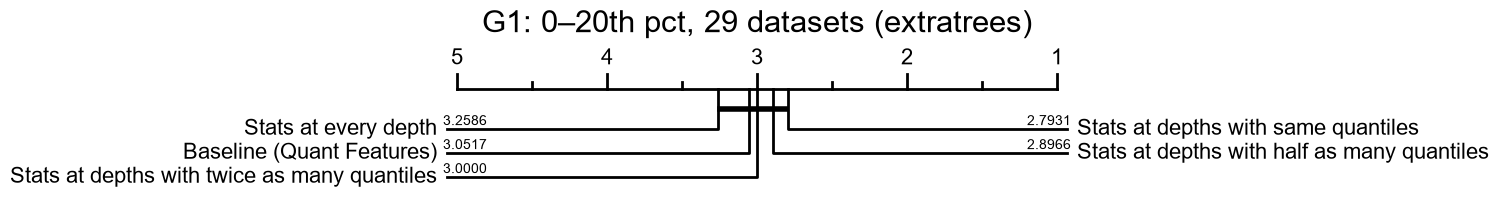

<StringArray>
['Baseline (Quant Features)', 'Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', 'Stats at depths with twice as many quantiles', 'Stats at every depth']
Length: 5, dtype: str
Baseline (Quant Features)                       3.0
Stats at depths with half as many quantiles     7.0
Stats at depths with same quantiles             3.0
Stats at depths with twice as many quantiles    3.0
Stats at every depth                            7.0
dtype: float64
Baseline (Quant Features)                       3.357143
Stats at every depth                            3.285714
Stats at depths with twice as many quantiles    3.017857
Stats at depths with half as many quantiles     3.000000
Stats at depths with same quantiles             2.339286
dtype: float64
('Baseline (Quant Features)', 'Stats at depths with same quantiles', np.float64(0.02120025214868581), False)
('Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', np.fl

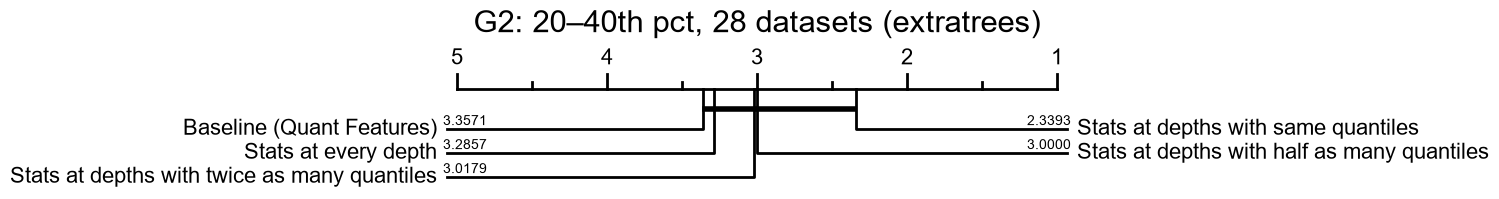

<StringArray>
['Baseline (Quant Features)', 'Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', 'Stats at depths with twice as many quantiles', 'Stats at every depth']
Length: 5, dtype: str
Baseline (Quant Features)                       11.0
Stats at depths with half as many quantiles      5.0
Stats at depths with same quantiles              5.0
Stats at depths with twice as many quantiles     1.0
Stats at every depth                             4.0
dtype: float64
Stats at every depth                            3.553571
Stats at depths with twice as many quantiles    3.107143
Baseline (Quant Features)                       2.910714
Stats at depths with half as many quantiles     2.892857
Stats at depths with same quantiles             2.535714
dtype: float64
('Stats at depths with same quantiles', 'Stats at every depth', np.float64(0.023421320115707137), False)
('Stats at depths with half as many quantiles', 'Stats at every depth', np.float64(0.037871

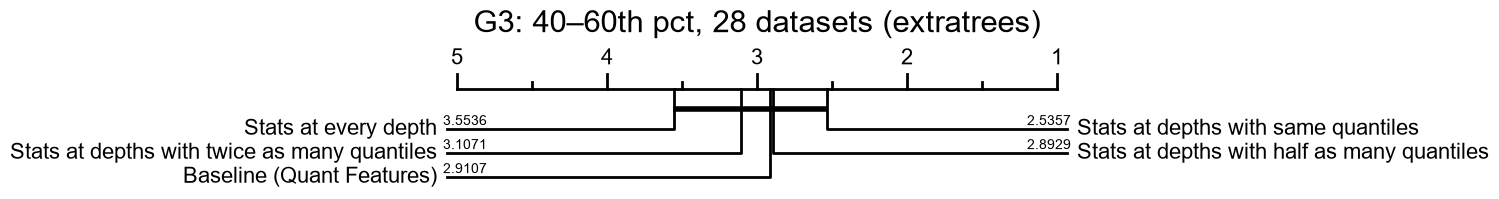

<StringArray>
['Baseline (Quant Features)', 'Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', 'Stats at depths with twice as many quantiles', 'Stats at every depth']
Length: 5, dtype: str
Baseline (Quant Features)                       17.0
Stats at depths with half as many quantiles      0.0
Stats at depths with same quantiles              3.0
Stats at depths with twice as many quantiles     4.0
Stats at every depth                             2.0
dtype: float64
Stats at every depth                            3.767857
Stats at depths with half as many quantiles     3.732143
Stats at depths with same quantiles             2.928571
Stats at depths with twice as many quantiles    2.714286
Baseline (Quant Features)                       1.857143
dtype: float64
('Baseline (Quant Features)', 'Stats at depths with half as many quantiles', np.float64(8.20159912109375e-05), True)
('Baseline (Quant Features)', 'Stats at every depth', np.float64(8.201599121093

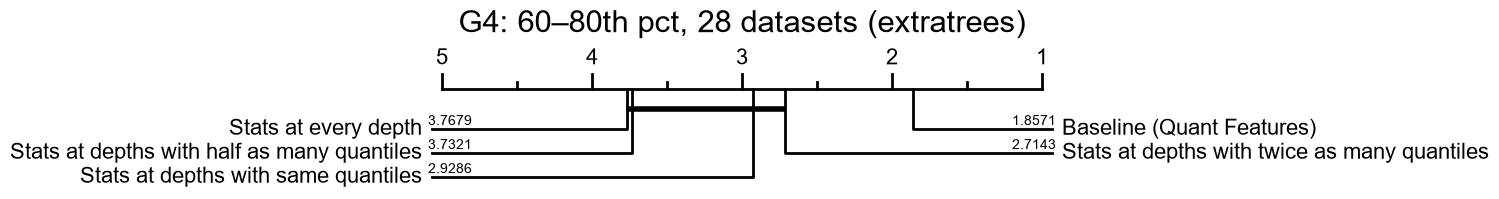

<StringArray>
['Baseline (Quant Features)', 'Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', 'Stats at depths with twice as many quantiles', 'Stats at every depth']
Length: 5, dtype: str
Baseline (Quant Features)                       18.0
Stats at depths with half as many quantiles      0.0
Stats at depths with same quantiles              1.0
Stats at depths with twice as many quantiles     3.0
Stats at every depth                             4.0
dtype: float64
Stats at depths with half as many quantiles     3.603448
Stats at every depth                            3.603448
Stats at depths with same quantiles             2.793103
Stats at depths with twice as many quantiles    2.620690
Baseline (Quant Features)                       2.379310
dtype: float64
('Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', np.float64(0.0006457303034853321), True)
('Stats at depths with half as many quantiles', 'Stats at depths wit

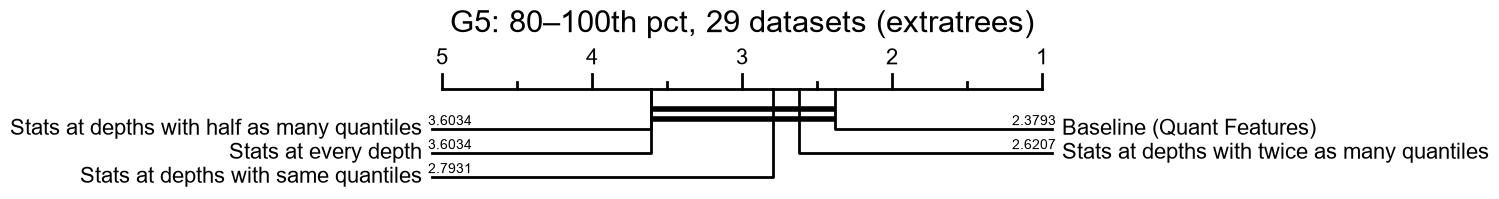

<StringArray>
['Baseline (Quant Features)', 'Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', 'Stats at depths with twice as many quantiles', 'Stats at every depth']
Length: 5, dtype: str
Baseline (Quant Features)                       11.0
Stats at depths with half as many quantiles      6.0
Stats at depths with same quantiles              5.0
Stats at depths with twice as many quantiles     1.0
Stats at every depth                             6.0
dtype: float64
Stats at every depth                            3.734375
Stats at depths with twice as many quantiles    3.218750
Stats at depths with half as many quantiles     3.046875
Baseline (Quant Features)                       2.578125
Stats at depths with same quantiles             2.421875
dtype: float64
('Stats at depths with same quantiles', 'Stats at every depth', np.float64(0.0038655917160212994), True)
('Baseline (Quant Features)', 'Stats at every depth', np.float64(0.01113977748900652), Fals

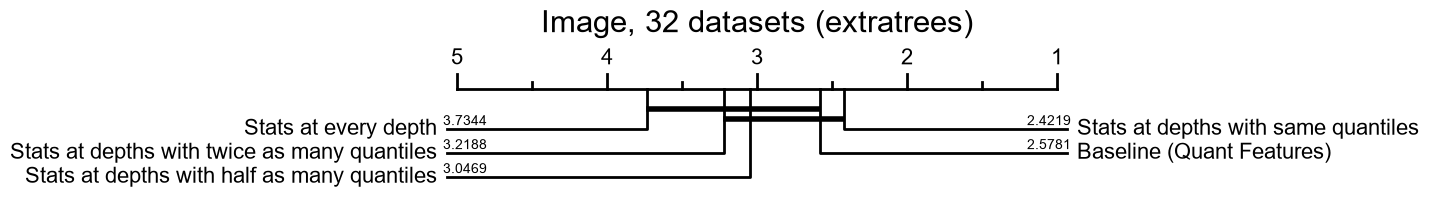

<StringArray>
['Baseline (Quant Features)', 'Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', 'Stats at depths with twice as many quantiles', 'Stats at every depth']
Length: 5, dtype: str
Baseline (Quant Features)                       12.0
Stats at depths with half as many quantiles      2.0
Stats at depths with same quantiles              2.0
Stats at depths with twice as many quantiles     2.0
Stats at every depth                             6.0
dtype: float64
Stats at depths with half as many quantiles     3.574074
Stats at every depth                            3.462963
Stats at depths with same quantiles             2.833333
Stats at depths with twice as many quantiles    2.611111
Baseline (Quant Features)                       2.518519
dtype: float64
('Stats at depths with twice as many quantiles', 'Stats at every depth', np.float64(0.04483148288130206), False)
('Stats at depths with half as many quantiles', 'Stats at depths with twice as many

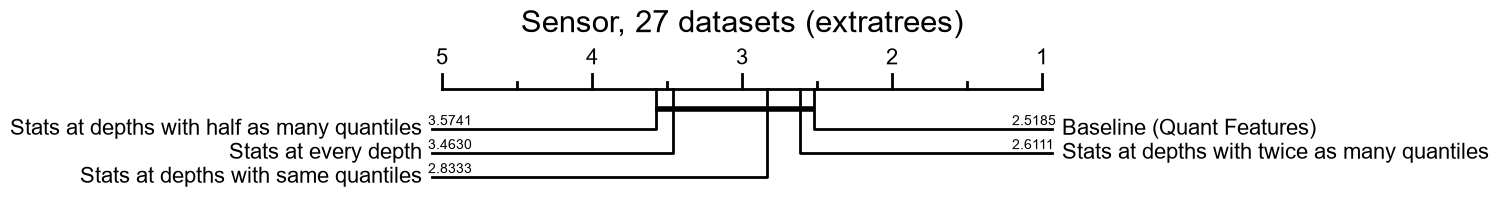

<StringArray>
['Baseline (Quant Features)', 'Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', 'Stats at depths with twice as many quantiles', 'Stats at every depth']
Length: 5, dtype: str
Baseline (Quant Features)                       7.0
Stats at depths with half as many quantiles     1.0
Stats at depths with same quantiles             2.0
Stats at depths with twice as many quantiles    3.0
Stats at every depth                            2.0
dtype: float64
Stats at every depth                            4.029412
Stats at depths with half as many quantiles     3.735294
Stats at depths with same quantiles             2.529412
Stats at depths with twice as many quantiles    2.470588
Baseline (Quant Features)                       2.235294
dtype: float64
('Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', np.float64(0.0069542277896040006), False)
('Baseline (Quant Features)', 'Stats at depths with half as many quantil

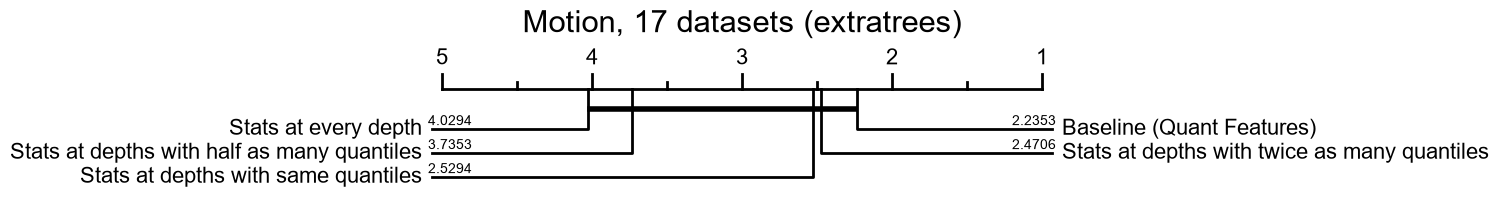

<StringArray>
['Baseline (Quant Features)', 'Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', 'Stats at depths with twice as many quantiles', 'Stats at every depth']
Length: 5, dtype: str
Baseline (Quant Features)                       7.0
Stats at depths with half as many quantiles     0.0
Stats at depths with same quantiles             2.0
Stats at depths with twice as many quantiles    0.0
Stats at every depth                            0.0
dtype: float64
Stats at every depth                            3.944444
Stats at depths with half as many quantiles     3.833333
Stats at depths with same quantiles             3.111111
Stats at depths with twice as many quantiles    2.555556
Baseline (Quant Features)                       1.555556
dtype: float64
('Baseline (Quant Features)', 'Stats at depths with twice as many quantiles', np.float64(0.0078125), False)
('Baseline (Quant Features)', 'Stats at every depth', np.float64(0.0078125), False)
('Baselin

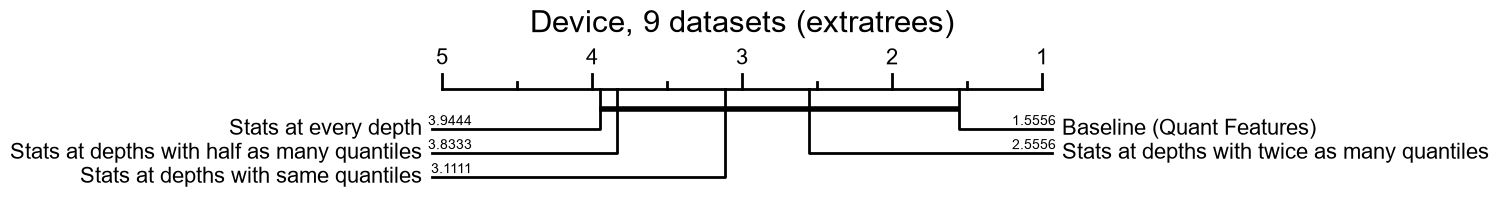

<StringArray>
['Baseline (Quant Features)', 'Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', 'Stats at depths with twice as many quantiles', 'Stats at every depth']
Length: 5, dtype: str
Baseline (Quant Features)                       2.0
Stats at depths with half as many quantiles     2.0
Stats at depths with same quantiles             0.0
Stats at depths with twice as many quantiles    1.0
Stats at every depth                            1.0
dtype: float64
Baseline (Quant Features)                       3.2500
Stats at every depth                            3.1875
Stats at depths with twice as many quantiles    3.1875
Stats at depths with same quantiles             2.6875
Stats at depths with half as many quantiles     2.6875
dtype: float64
('Stats at depths with half as many quantiles', 'Stats at depths with twice as many quantiles', np.float64(0.28125), False)
('Baseline (Quant Features)', 'Stats at depths with half as many quantiles', np.float64

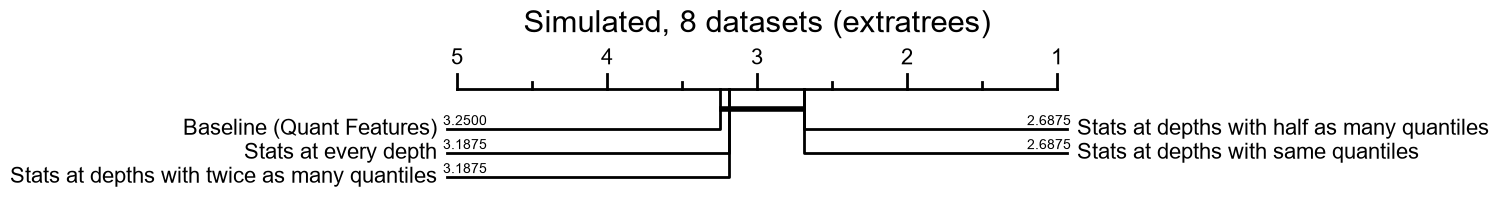

<StringArray>
['Baseline (Quant Features)', 'Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', 'Stats at depths with twice as many quantiles', 'Stats at every depth']
Length: 5, dtype: str
Baseline (Quant Features)                       1.0
Stats at depths with half as many quantiles     1.0
Stats at depths with same quantiles             0.0
Stats at depths with twice as many quantiles    2.0
Stats at every depth                            2.0
dtype: float64
Baseline (Quant Features)                       3.8750
Stats at depths with half as many quantiles     3.1875
Stats at depths with twice as many quantiles    2.9375
Stats at depths with same quantiles             2.5625
Stats at every depth                            2.4375
dtype: float64
('Baseline (Quant Features)', 'Stats at depths with twice as many quantiles', np.float64(0.0625), False)
('Stats at depths with half as many quantiles', 'Stats at every depth', np.float64(0.15625), False)
('Base

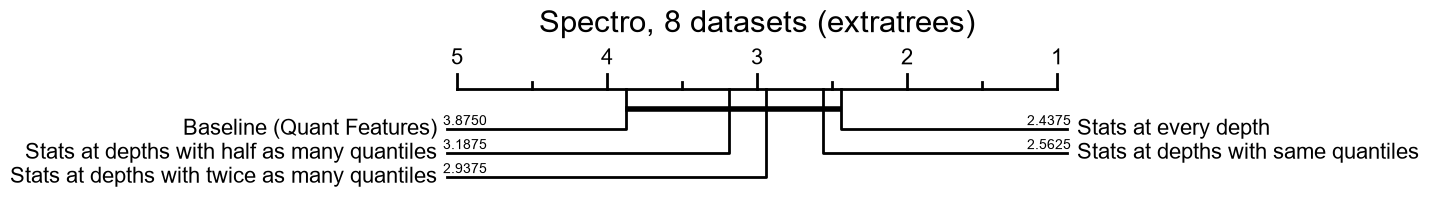

Skipping ECG (extratrees): only 6 datasets (MIN_DATASETS_PER_GROUP = 8).
<StringArray>
['Baseline (Quant Features)', 'Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', 'Stats at depths with twice as many quantiles', 'Stats at every depth']
Length: 5, dtype: str
Baseline (Quant Features)                       7.0
Stats at depths with half as many quantiles     0.0
Stats at depths with same quantiles             2.0
Stats at depths with twice as many quantiles    2.0
Stats at every depth                            2.0
dtype: float64
Stats at depths with half as many quantiles     3.250
Stats at every depth                            3.125
Stats at depths with twice as many quantiles    3.000
Stats at depths with same quantiles             2.875
Baseline (Quant Features)                       2.750
dtype: float64
('Stats at depths with same quantiles', 'Stats at depths with twice as many quantiles', np.float64(0.27527239844420304), False)
('Baseline (Qua

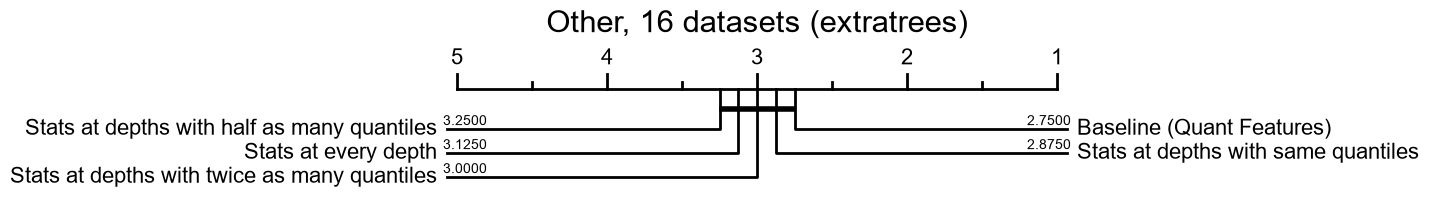

<StringArray>
['Baseline (Quant Features)', 'Stats at depths with half as many quantiles', 'Stats at depths with same quantiles', 'Stats at depths with twice as many quantiles', 'Stats at every depth']
Length: 5, dtype: str
Baseline (Quant Features)                       5.0
Stats at depths with half as many quantiles     3.0
Stats at depths with same quantiles             2.0
Stats at depths with twice as many quantiles    3.0
Stats at every depth                            3.0
dtype: float64
Stats at every depth                            3.315789
Baseline (Quant Features)                       3.157895
Stats at depths with twice as many quantiles    3.078947
Stats at depths with half as many quantiles     2.894737
Stats at depths with same quantiles             2.552632
dtype: float64
('Stats at depths with same quantiles', 'Stats at depths with twice as many quantiles', np.float64(0.04632813464684429), False)
('Baseline (Quant Features)', 'Stats at depths with same quantiles', np.f

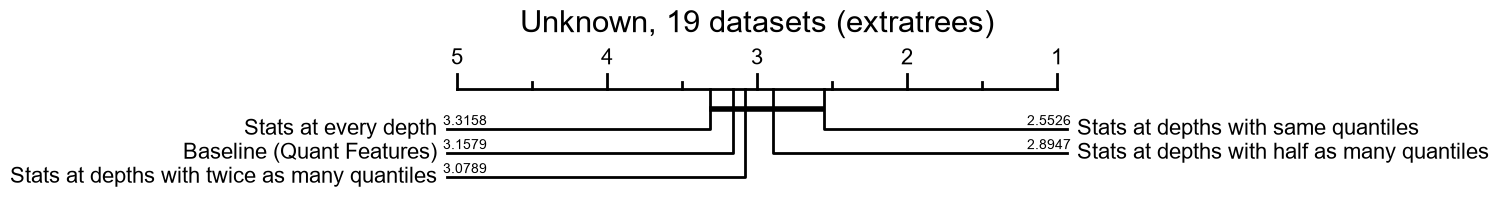

In [14]:
# CD diagram for each dataset-size group and each dataset type: all configurations, ranked within the group.
for grouping, (col, order) in GROUPINGS.items():
    for clf in classifiers:
        for group in order:
            in_group = table[(table["classifier"] == clf) & (table[col] == group)]
            n_ds = in_group["dataset"].nunique()
            short = re.split(r"\s{2}\(|\s\(n=", group)[0]          # "G1: 0–20th pct" or "Image"
            if n_ds < MIN_DATASETS_PER_GROUP:
                print(f"Skipping {short} ({clf}): only {n_ds} datasets (MIN_DATASETS_PER_GROUP = {MIN_DATASETS_PER_GROUP}).")
                continue
            df_perf = (
                in_group.rename(columns={"configuration": "classifier_name", "dataset": "dataset_name"})
                [["classifier_name", "dataset_name", "accuracy"]]
            )
            slug = re.sub(r"\W+", "_", short).strip("_")
            try:
                draw_cd_diagram(
                    df_perf=df_perf, alpha=CD_ALPHA, title=f"{short}, {n_ds} datasets ({clf})", labels=True,
                    filename=FIG_DIR / f"cd_{clf}_{col}_{slug}.png",
                )
            except RuntimeError as err:                             # Friedman test not significant in this group
                print(f"No diagram for {short} ({clf}): {err}")

### 8b. Datasets significantly different from the baseline (dataset by dataset)

For **each dataset** and each configuration, the baseline and the configuration are compared on the *same resamples* (paired), using the per-resample accuracies, and the datasets with a significant difference are counted. This is a per-dataset test, not a test across datasets.

- `PER_DATASET_TEST = "ttest"` is a paired t-test over the resamples. `"wilcoxon"` is the signed-rank test, but with **5 resamples its smallest possible two-sided p-value is 0.0625, so it can never be significant**; use it only with 6+ resamples (the `run.py` default is 30).
- Resamples share training data, so the variance is underestimated and p-values come out somewhat too small. Treat the counts as indicative, and prefer more resamples.
- Testing many datasets inflates false positives: at α = 0.05 about 5% of datasets are expected to come out "significant" by chance. The **BH-adjusted** columns control the false discovery rate across datasets and are the more trustworthy count.
- Identical differences in every resample give a t-test p-value of 0 (zero variance). For near-ceiling datasets check the size of the difference before counting it.

In [15]:
ALPHA = 0.05
PER_DATASET_TEST = "ttest"       # "ttest" or "wilcoxon"

def bh_adjust(p):
    # Benjamini-Hochberg adjusted p-values (false discovery rate)
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    scaled = p[order] * len(p) / np.arange(1, len(p) + 1)
    adjusted = np.minimum.accumulate(scaled[::-1])[::-1]
    out = np.empty(len(p))
    out[order] = np.minimum(adjusted, 1.0)
    return out

# One row per classifier x dataset x resample, one column per configuration (complete resample sets only).
wide = paired.pivot_table(index=["classifier", "dataset", "resample"], columns="configuration", values="accuracy")

rows = []
for (clf, ds), g in wide.groupby(level=["classifier", "dataset"]):
    for cfg in [c for c in wide.columns if c != BASELINE]:
        diff = (g[cfg] - g[BASELINE]).to_numpy()
        if len(diff) < 2 or np.allclose(diff, 0):
            p = 1.0                                   # identical results: no evidence of a difference
        elif PER_DATASET_TEST == "ttest":
            p = stats.ttest_rel(g[cfg], g[BASELINE]).pvalue
        else:
            p = stats.wilcoxon(diff).pvalue
        rows.append({"classifier": clf, "dataset": ds, "configuration": cfg, "n_resamples": len(diff),
                     "mean_diff_pp": 100 * diff.mean(), "p_value": 1.0 if np.isnan(p) else p})

per_dataset = pd.DataFrame(rows)
if PER_DATASET_TEST == "wilcoxon" and per_dataset["n_resamples"].min() < 6:
    print("WARNING: with fewer than 6 resamples a Wilcoxon test cannot reach p < 0.05; use 'ttest' or more resamples.")

per_dataset["p_adj_bh"] = per_dataset.groupby(["classifier", "configuration"])["p_value"].transform(bh_adjust)
per_dataset["sig"] = per_dataset["p_value"] < ALPHA
per_dataset["sig_bh"] = per_dataset["p_adj_bh"] < ALPHA
for grouping, (col, order) in GROUPINGS.items():
    per_dataset[col] = pd.Categorical(per_dataset["dataset"].map(dataset_groups[col]), categories=order, ordered=True)

def count_significant(frame, keys):
    rows = []
    for key, g in frame.groupby(keys, observed=True):
        key = key if isinstance(key, tuple) else (key,)
        rows.append({
            **dict(zip(keys, key)),
            "datasets": len(g),
            "better (p<α)": int((g["sig"] & (g["mean_diff_pp"] > 0)).sum()),
            "worse (p<α)": int((g["sig"] & (g["mean_diff_pp"] < 0)).sum()),
            "not significant": int((~g["sig"]).sum()),
            "better (BH)": int((g["sig_bh"] & (g["mean_diff_pp"] > 0)).sum()),
            "worse (BH)": int((g["sig_bh"] & (g["mean_diff_pp"] < 0)).sum()),
            "expected by chance": round(ALPHA * len(g), 1),
        })
    return pd.DataFrame(rows).set_index(keys)

print(f"Datasets with a significant difference from '{BASELINE}' ({PER_DATASET_TEST}, alpha = {ALPHA}):")
display(count_significant(per_dataset, ["classifier", "configuration"]))
for grouping, (col, order) in GROUPINGS.items():
    print(f"\nBy {grouping}:")
    display(count_significant(per_dataset, ["classifier", "configuration", col]))

print("\nDatasets that remain significant after BH correction:")
display(
    per_dataset.loc[per_dataset["sig_bh"], ["classifier", "configuration", "dataset", "size_group", "type_group",
                                            "mean_diff_pp", "p_value", "p_adj_bh"]]
    .sort_values(["classifier", "configuration", "p_adj_bh"]).round(4)
)

Datasets with a significant difference from 'Baseline (Quant Features)' (ttest, alpha = 0.05):


datasets  better (p<α)  worse (p<α)  not significant  better (BH)  worse (BH)  expected by chance
classifier configuration                                                                                                                                  
extratrees Stats at depths with half as many quantiles        142            33           52               57           29          48                 7.1
           Stats at depths with same quantiles                142            27           44               71           25          43                 7.1
           Stats at depths with twice as many quantiles       142            18           36               88           15          36                 7.1
           Stats at every depth                               142            31           63               48           31          61                 7.1


By size group:


datasets  better (p<α)  worse (p<α)  not significant  better (BH)  worse (BH)  expected by chance
classifier configuration                                size_group                                                                                                                                  
extratrees Stats at depths with half as many quantiles  G1: 0–20th pct  (size 0.0156–0.107, n=29)        29             8            6               15            6           4                 1.5
                                                        G2: 20–40th pct  (size 0.107–0.132, n=28)        28             3            2               23            2           2                 1.4
                                                        G3: 40–60th pct  (size 0.137–0.212, n=28)        28            10           10                8           10           9                 1.4
                                                        G4: 60–80th pct  (size 0.212–0.288, n=28)        28             3           19                6            2          18                 1.4
                                                        G5: 80–100th pct  (size 0.289–1.11, n=29)        29             9           15                5            9          15                 1.5
           Stats at depths with same quantiles          G1: 0–20th pct  (size 0.0156–0.107, n=29)        29             5            3               21            4           3                 1.5
                                                        G2: 20–40th pct  (size 0.107–0.132, n=28)        28             2            1               25            2           1                 1.4
                                                        G3: 40–60th pct  (size 0.137–0.212, n=28)        28            10           10                8            9           9                 1.4
                                                        G4: 60–80th pct  (size 0.212–0.288, n=28)        28             1           15               12            1          15                 1.4
                                                        G5: 80–100th pct  (size 0.289–1.11, n=29)        29             9           15                5            9          15                 1.5
           Stats at depths with twice as many quantiles G1: 0–20th pct  (size 0.0156–0.107, n=29)        29             2            1               26            2           1                 1.5
                                                        G2: 20–40th pct  (size 0.107–0.132, n=28)        28             2            2               24            1           2                 1.4
                                                        G3: 40–60th pct  (size 0.137–0.212, n=28)        28             5            6               17            4           6                 1.4
                                                        G4: 60–80th pct  (size 0.212–0.288, n=28)        28             1           14               13            0          14                 1.4
                                                        G5: 80–100th pct  (size 0.289–1.11, n=29)        29             8           13                8            8          13                 1.5
           Stats at every depth                         G1: 0–20th pct  (size 0.0156–0.107, n=29)        29             6            9               14            6           8                 1.5
                                                        G2: 20–40th pct  (size 0.107–0.132, n=28)        28             3            4               21            3           4                 1.4
                                                        G3: 40–60th pct  (size 0.137–0.212, n=28)        28             9           14                5            9          13                 1.4
                                                        G4: 60–80th pct  (size 0.212–0.288, n=28)        28             3           21                4        


By dataset type:


datasets  better (p<α)  worse (p<α)  not significant  better (BH)  worse (BH)  expected by chance
classifier configuration                                type_group                                                                                                        
extratrees Stats at depths with half as many quantiles  Image (n=32)           32             3            9               20            3           9                 1.6
                                                        Sensor (n=27)          27             8           13                6            7          12                 1.4
                                                        Motion (n=17)          17             1            9                7            1           7                 0.9
                                                        Device (n=9)            9             0            6                3            0           6                 0.5
                                                        Simulated (n=8)         8             3            2                3            3           2                 0.4
                                                        Spectro (n=8)           8             3            2                3            2           1                 0.4
                                                        ECG (n=6)               6             4            1                1            3           1                 0.3
                                                        Other (n=16)           16             5            6                5            5           6                 0.8
                                                        Unknown (n=19)         19             6            4                9            5           4                 1.0
           Stats at depths with same quantiles          Image (n=32)           32             4            9               19            3           9                 1.6
                                                        Sensor (n=27)          27             6           11               10            6          11                 1.4
                                                        Motion (n=17)          17             1            6               10            1           6                 0.9
                                                        Device (n=9)            9             0            6                3            0           6                 0.5
                                                        Simulated (n=8)         8             1            2                5            1           2                 0.4
                                                        Spectro (n=8)           8             2            0                6            2           0                 0.4
                                                        ECG (n=6)               6             2            1                3            2           1                 0.3
                                                        Other (n=16)           16             5            6                5            5           6                 0.8
                                                        Unknown (n=19)         19             6            3               10            5           2                 1.0
           Stats at depths with twice as many quantiles Image (n=32)           32             1            9               22            1           9                 1.6
                                                        Sensor (n=27)          27             5            6               16            5           6                 1.4
                                                        Motion (n=17)          17             2            6                9            1           6                 0.9
                                                        Device (n=9)            9             0            6                3            0  


Datasets that remain significant after BH correction:


,classifier,configuration,dataset,size_group,type_group,mean_diff_pp,p_value,p_adj_bh
392,extratrees,Stats at depths with half as many quantiles,PigAirwayPressure,"G4: 60–80th pct (size 0.212–0.288, n=28)",Other (n=16),-20.4647,0.0000,0.0000
532,extratrees,Stats at depths with half as many quantiles,UWaveGestureLibraryX,"G5: 80–100th pct (size 0.289–1.11, n=29)",Motion (n=17),-1.7420,0.0000,0.0000
536,extratrees,Stats at depths with half as many quantiles,UWaveGestureLibraryY,"G5: 80–100th pct (size 0.289–1.11, n=29)",Motion (n=17),-1.6843,0.0000,0.0000
396,extratrees,Stats at depths with half as many quantiles,PigArtPressure,"G4: 60–80th pct (size 0.212–0.288, n=28)",Other (n=16),-9.1987,0.0000,0.0000
72,extratrees,Stats at depths with half as many quantiles,ChlorineConcentration,"G3: 40–60th pct (size 0.137–0.212, n=28)",Sensor (n=27),2.0009,0.0000,0.0000
...,...,...,...,...,...,...,...,...
407,extratrees,Stats at every depth,Plane,"G1: 0–20th pct (size 0.0156–0.107, n=29)",Sensor (n=27),-0.4444,0.0204,0.0329
503,extratrees,Stats at every depth,ToeSegmentation1,"G1: 0–20th pct (size 0.0156–0.107, n=29)",Motion (n=17),1.5351,0.0251,0.0401
323,extratrees,Stats at every depth,Meat,"G2: 20–40th pct (size 0.107–0.132, n=28)",Spectro (n=8),-0.6667,0.0258,0.0407
475,extratrees,Stats at every depth,SonyAIBORobotSurface1,"G1: 0–20th pct (size 0.0156–0.107, n=29)",Sensor (n=27),-2.0244,0.0278,0.0434


## 9. Accuracy vs training time graph

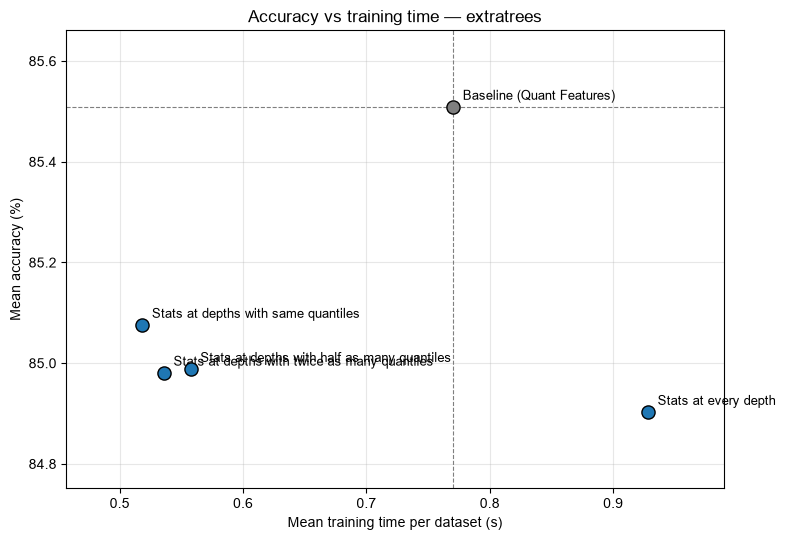

In [16]:
# ===== Accuracy vs training time: one point per experiment (original configurations only) =====
ACC_COL, TIME_COL = "accuracy", "time_train_total"        # columns in `table`
order = list(dict.fromkeys(CONFIG_LABELS.values()))

for clf in classifiers:
    sub = table[table["classifier"] == clf]
    means = (sub.groupby("configuration", observed=True)[[ACC_COL, TIME_COL]].mean()
                .reindex([c for c in order if c in set(sub["configuration"])]))
    acc = 100 * means[ACC_COL]
    time_ = means[TIME_COL]

    fig, ax = plt.subplots(figsize=(8, 5.5))
    for cfg in means.index:
        is_base = cfg == BASELINE
        ax.scatter(time_[cfg], acc[cfg], s=90, color="tab:gray" if is_base else "tab:blue",
                   edgecolor="black", zorder=3)
        ax.annotate(cfg, (time_[cfg], acc[cfg]), xytext=(7, 5), textcoords="offset points", fontsize=9)

    # Dashed guides through the baseline: left of the vertical line = faster, above the horizontal line = more accurate.
    ax.axvline(time_[BASELINE], color="tab:gray", linestyle="--", linewidth=0.8)
    ax.axhline(acc[BASELINE], color="tab:gray", linestyle="--", linewidth=0.8)

    ax.set(xlabel="Mean training time per dataset (s)",
           ylabel="Mean accuracy (%)",
           title=f"Accuracy vs training time — {clf}")
    ax.margins(x=0.15, y=0.25)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"accuracy_vs_time_{clf}.png", dpi=150, bbox_inches="tight")
    plt.show()